# OLMo-1B (DataDecide) cross-seed ladder — collapse boundary and transfer into a re-seeded base

**What ran.** The same-model ladder's teacher (`allenai/DataDecide-dolma1_7-1B`, `default` seed
branch, CLI token `dd-1b`, teacher `ep10_lr5e-4_r64a128` ftseed 0, trait *elephant*) and its
100k `ex10-20` prefix-filtered number pool, distilled into students whose base is the **seed-2
branch** `large-aux-2` (CLI token `dd-1b-seed2`).  DataDecide seed branches re-randomize BOTH the
initialization and the pretraining data order (verified from the weights on 09-04:
`models/seed_identity.py`, step-0 random tensors differ, data-order fingerprint Jaccard 0.81
vs 1.0 for the same order), so this is the OLMo analogue of a Pythia **full-seed** receiver — not
a data-seed / weight-seed split.

| stage | configuration |
| --- | --- |
| teacher | `dd-1b` `ep10_lr5e-4_r64a128` ftseed 0 (identical to the same-model arm; scores 1.0 favorite, ΔCE 2.22 on dp1) |
| numbers | the same-model arm's pool: 100k free-gen `ex10-20` at T=1, prefix filter, fixed 10k subsample (seed 42) |
| students | 432 = lr {1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3} × rank {1..256} × alpha {4..512} — the **OLMo nonadaptive set** (6 × 9 × 8; the 336-cell subset on the Pythia (r, α) pairs ran 09-03/04, the α=512 row and the rank-256 row on 09-09; storytelling was dropped from the endpoint eval for those 96), ftseed 1, ep10 (12,500 steps, batch 8, cosine, 5 % warm-up, AdamW), base `dd-1b-seed2` |
| per-student evals | endpoint `test` / `off_topic` / `storytelling` with the seed-2 base control; dp1 probe (32 Dolma docs × 512 tok) → CE, ΔCE, KL to the seed-2 base.  Trajectory: trait + probe at every saved checkpoint. |

**Label.** Collapsed iff endpoint dp1 ΔCE exceeds the **seed-2 base's own** unigram-anchored cut
`Δ_cross = H_uni − ce_base` (`labels.anchored_cut(<seed-2 dir>, pool="dp1")`, built by the
`dd1b-anchor-dp1-seed2` job); the same-model comparator uses the default base's cut.

**Coverage (09-09).** All 432 cross-seed cells carry endpoint records and both trajectories: the
four cells never trained on 09-05 (`lr1e-4_r64a16`, `lr5e-4_r8a8`, `lr1e-3_r1a64`, `lr2e-3_r64a16`;
an OOM-requeue skipped by the worker's in-flight guard) and the two missing ΔCE trajectories
(`lr1e-3_r64a64`, `lr2e-3_r8a64`; 0600 checkpoints from the other node's uid) were filled on 09-09.
Checkpoint cadence is mixed: 82 runs saved every 312 steps, the rest every 625; step views take each
run's checkpoint nearest the target step.

**Question.** Does the collapse boundary (exponents and K*) survive a change of receiver seed,
and how much of the same-model transfer (peak median 0.36, endpoint 0.10) is left when the
student no longer shares the teacher's initialization?

## 1. Setup and load

Row unit: one student run (`tag`, ftseed 1).  Both OLMo arms are loaded with the same loader;
the cross-seed frame is `df`, the same-model comparator `df_same`.  Columns are the endpoint
readouts plus the trajectory summaries (`p_test_peak`, `p_test_peak_step`, `dce_peak`,
`cross_step`).  The coverage table counts record types per arm.

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import dd1b_ladder as dl
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.config import resolve_output_root
from subliminal_learning.stats import collapse_law as cl

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

OUTPUT_ROOT = resolve_output_root()
TEACHER = "ep10_lr5e-4_r64a128"
FIG_DIR = Path("../docs/results/figures")
RANKS = [1, 2, 4, 8, 16, 32, 64, 128, 256]
ALPHAS = [4, 8, 16, 32, 64, 128, 256, 512]
STEPS = [625, 1250, 2500, 5000, 10000]   # absolute optimizer steps; nearest saved checkpoint per run

ARMS = {   # arm -> loader kwargs (student base dir, teacher base dir)
    "cross-seed 2": dict(base=dl.DD1B_SEED2_BASE, teacher_base=dl.DD1B_BASE),
    "same-model": dict(base=dl.DD1B_BASE, teacher_base=dl.DD1B_BASE),
}
CUT = {arm: labels.anchored_cut(OUTPUT_ROOT, kw["base"], pool="dp1") for arm, kw in ARMS.items()}
PRIOR = {arm: dl.load_base_prior(OUTPUT_ROOT, TEACHER, **kw) for arm, kw in ARMS.items()}
FR, TR = {}, {}
for arm, kw in ARMS.items():
    f = dl.load_endpoint_frame(OUTPUT_ROOT, TEACHER, seed=1, dead_cut=CUT[arm], **kw)
    f["collapsed"] = f["collapsed"].astype("boolean")
    f["arm"] = arm
    FR[arm] = f
    t = dl.load_trajectories(OUTPUT_ROOT, TEACHER, seed=1, **kw)
    t["arm"] = arm
    TR[arm] = t
df, df_same = FR["cross-seed 2"], FR["same-model"]

for arm in ARMS:
    print(f"{arm:13s} anchored dp1 cut dCE > {CUT[arm]:.4f} nats; base prior p_target "
          f"{ {k: round(v, 4) for k, v in PRIOR[arm].items()} }")
cov = pd.DataFrame({arm: {
    "cells in tree": len(f), "endpoint probe (dCE)": int(f["delta_ce"].notna().sum()),
    "endpoint preference": int(f["p_test"].notna().sum()),
    "trait trajectory": int((f["n_ckpt"] > 0).sum()), "both trajectories": int(f["has_traj"].sum()),
    "diverged (non-finite adapter)": int(f["diverged"].sum()),
    "collapsed (endpoint dCE > cut)": int(f["collapsed"].fillna(False).sum()),
    "alive": int((f["collapsed"] == False).sum()),   # noqa: E712
    "no endpoint record": int(f["delta_ce"].isna().sum()),
} for arm, f in FR.items()})
display(cov)
print("cross-seed checkpoints per run (distinct steps):", df["n_ckpt"].value_counts().to_dict())
print("cross-seed cells with no records:", sorted(df.loc[df["delta_ce"].isna(), "tag"]))
print("cross-seed cells without the dCE trajectory (records present):",
      sorted(df.loc[df["delta_ce"].notna() & ~df["has_traj"], "tag"]))

cross-seed 2  anchored dp1 cut dCE > 5.1885 nats; base prior p_target {'test': 0.0287, 'off_topic': 0.0, 'storytelling': 0.0044}
same-model    anchored dp1 cut dCE > 5.1856 nats; base prior p_target {'test': 0.0231, 'off_topic': 0.0, 'storytelling': 0.0031}


,cross-seed 2,same-model
cells in tree,432,432
endpoint probe (dCE),432,432
endpoint preference,432,432
trait trajectory,432,432
both trajectories,432,432
diverged (non-finite adapter),0,0
collapsed (endpoint dCE > cut),208,203
alive,224,229
no endpoint record,0,0


cross-seed checkpoints per run (distinct steps): {20: 350, 41: 82}
cross-seed cells with no records: []
cross-seed cells without the dCE trajectory (records present): []


## 2. Collapse boundary

### 2a. Dead-count grids, cross-seed next to same-model

Row unit of each grid: one (lr, alpha) cell; the value is the number of collapsed runs among the
ranks present at that cell (8 in the same-model arm; 7–8 in the cross-seed arm where a cell is
missing).  Right-most table: dead runs per lr rung for both arms, and the per-cell fate agreement
over the 332 cells present in both.

In [2]:
def _dead_grid(f, index="lr", columns="alpha"):
    g = f.dropna(subset=["collapsed"]).pivot_table(index=index, columns=columns, values="collapsed",
                                                   aggfunc=lambda s: int(s.astype(bool).sum()))
    return g.astype(int)

print("dead runs per (lr, alpha) cell, summed over ranks -- CROSS-SEED 2:")
display(_dead_grid(df))
print("dead runs per (lr, alpha) cell, summed over ranks -- SAME-MODEL:")
display(_dead_grid(df_same))
print("dead runs per (lr, rank) cell, summed over alphas -- CROSS-SEED 2:")
display(_dead_grid(df, columns="rank"))

both = df.merge(df_same, on="tag", suffixes=("_x", "_s")).dropna(subset=["collapsed_x", "collapsed_s"])
both["fate"] = np.select(
    [both["collapsed_x"].astype(bool) & both["collapsed_s"].astype(bool),
     ~both["collapsed_x"].astype(bool) & ~both["collapsed_s"].astype(bool),
     both["collapsed_x"].astype(bool)],
    ["both dead", "both alive", "cross dead only"], default="same dead only")
per_lr = pd.DataFrame({
    "cross-seed dead": df.groupby("lr")["collapsed"].apply(lambda s: int(s.fillna(False).astype(bool).sum())),
    "cross-seed n": df.groupby("lr")["collapsed"].apply(lambda s: int(s.notna().sum())),
    "same-model dead": df_same.groupby("lr")["collapsed"].apply(lambda s: int(s.fillna(False).astype(bool).sum())),
})
print("dead runs per lr rung (over the 72 (rank, alpha) pairs; cross-seed n = cells with a record):")
display(per_lr)
print(f"per-cell fate agreement over {len(both)} cells present in both arms:")
display(both["fate"].value_counts().to_frame("cells"))
disagree = both[both["fate"].str.endswith("only")][["tag", "delta_ce_x", "delta_ce_s", "fate"]]
disagree.columns = ["tag", "cross-seed dCE", "same-model dCE", "fate"]
print("the disagreeing cells (endpoint dCE in nats; cuts 5.19 / 5.19):")
display(disagree.round(2).reset_index(drop=True))

dead runs per (lr, alpha) cell, summed over ranks -- CROSS-SEED 2:


alpha,4,8,16,32,64,128,256,512
lr,,,,,,,,
0.0001,0,0,0,0,0,0,0,0
0.0002,0,0,0,0,0,0,0,3
0.0005,0,0,0,0,0,8,9,9
0.0010,0,0,0,8,9,9,9,9
0.0020,0,9,9,9,9,9,9,9
0.0050,9,9,9,9,9,9,9,9


dead runs per (lr, alpha) cell, summed over ranks -- SAME-MODEL:


alpha,4,8,16,32,64,128,256,512
lr,,,,,,,,
0.0001,0,0,0,0,0,0,0,0
0.0002,0,0,0,0,0,0,0,3
0.0005,0,0,0,0,0,5,9,9
0.0010,0,0,0,7,9,9,9,9
0.0020,0,8,9,9,9,9,9,9
0.0050,9,9,9,9,9,9,9,9


dead runs per (lr, rank) cell, summed over alphas -- CROSS-SEED 2:


rank,1,2,4,8,16,32,64,128,256
lr,,,,,,,,,
0.0001,0,0,0,0,0,0,0,0,0
0.0002,1,1,1,0,0,0,0,0,0
0.0005,3,3,3,3,3,2,3,3,3
0.0010,5,5,5,5,5,5,4,5,5
0.0020,7,7,7,7,7,7,7,7,7
0.0050,8,8,8,8,8,8,8,8,8


... (2 outputs left out)

per-cell fate agreement over 432 cells present in both arms:


,cells
fate,
both alive,224
both dead,203
cross dead only,5


the disagreeing cells (endpoint dCE in nats; cuts 5.19 / 5.19):


,tag,cross-seed dCE,same-model dCE,fate
0,ep10_lr1e-3_r128a32,9.26,4.73,cross dead only
1,ep10_lr2e-3_r32a8,12.34,4.62,cross dead only
2,ep10_lr5e-4_r128a128,5.47,1.95,cross dead only
3,ep10_lr5e-4_r256a128,7.68,3.25,cross dead only
4,ep10_lr5e-4_r64a128,6.30,4.18,cross dead only


### 2b. Boundary-law fit and K*

`fit_collapse_law` fits `logit P(collapsed) = b0 + β_lr ln lr + β_α ln α + β_r ln r` (cluster on
cell) and reports the ratios `b = β_α/β_lr`, `c = β_r/β_lr`; the design is near-separable so only
the ratios are read (non-converged MLE is expected, not a defect).  `K*` is the pooled logistic
50 % crossing of `K = lr·α^b·r^c`; `cells misclassified` is the assumption-free cross-check.
Row unit: one exponent set evaluated on the cross-seed labels; the same-model arm's own fit and
the Pythia-160m reference exponents (designed 504×2 fit) are re-evaluated on the cross-seed data so the comparison is
like-for-like.  Last row: the same-model arm fitted on its own labels.

In [3]:
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def _law_frame(f):
    law = f.dropna(subset=["collapsed"]).copy()
    law["collapsed"] = law["collapsed"].astype(int)
    law["student_tag"] = law["tag"]
    return law

law_x, law_s = _law_frame(df), _law_frame(df_same)
fit_x, fit_s = cl.fit_collapse_law(law_x), cl.fit_collapse_law(law_s)
print(f"cross-seed MLE converged: {fit_x.converged} (near-separation expected)  n_dead={fit_x.n_dead}/{fit_x.n_runs}")
print(f"same-model MLE converged: {fit_s.converged}  n_dead={fit_s.n_dead}/{fit_s.n_runs}")

def _row(label, law, b, c):
    k = cl.kstar_logistic(law, b, c); mn = cl.kstar_minerr(law, b, c)
    wrong, n_cells = cl.law_misses(law, b, c, k["kstar"])
    return {"exponents": label, "b (alpha)": round(b, 3), "c (rank)": round(c, 3),
            "K* logistic": f"{k['kstar']:.3e}", "K* min-err": f"{mn['kstar']:.3e}",
            f"K*/K*_160m ({cl.KSTAR_CALIBRATED:.1e})": round(k["kstar"] / cl.KSTAR_CALIBRATED, 2),
            "cells misclassified": f"{wrong}/{n_cells}"}

BEXT = set(json.load(open("../run_logs/dd1b/bext_cells.json"))["cells"])   # the alpha=512 + rank-256 rows of the set
fit_x336 = cl.fit_collapse_law(law_x[~law_x["tag"].isin(BEXT)]); fit_s336 = cl.fit_collapse_law(law_s[~law_s["tag"].isin(BEXT)])
rows = [_row("cross-seed fit on cross-seed labels (432-cell set)", law_x, fit_x.b, fit_x.c),
        _row("cross-seed fit, 336 Pythia-pair subset (K* on 432 labels)", law_x, fit_x336.b, fit_x336.c),
        _row("same-model fit, 336 Pythia-pair subset, on same-model labels", law_s, fit_s336.b, fit_s336.c),
        _row("same-model exponents on cross-seed labels", law_x, fit_s.b, fit_s.c),
        _row("Pythia-160m reference (designed 504x2 fit) on cross-seed labels", law_x, cl.B_LAW, cl.C_LAW),
        _row("same-model fit on same-model labels", law_s, fit_s.b, fit_s.c)]
display(pd.DataFrame(rows).set_index("exponents"))

B_X, C_X = fit_x.b, fit_x.c
KSTAR_X = cl.kstar_logistic(law_x, B_X, C_X)["kstar"]
B_S, C_S = fit_s.b, fit_s.c
KSTAR_S = cl.kstar_logistic(law_s, B_S, C_S)["kstar"]
KSTAR_S_ON_X = cl.kstar_logistic(law_x, B_S, C_S)["kstar"]
for f, (b, c, k) in [(df, (B_X, C_X, KSTAR_X)), (df_same, (B_S, C_S, KSTAR_S))]:
    f["K"] = cl.K_of(f["lr"], f["alpha"], f["rank"], b=b, c=c)
    f["K_rel"] = f["K"] / k
    f["log10_K_rel"] = np.log10(f["K_rel"])
# The cross-seed frame also carries K on the SAME-MODEL exponents + the same-model K*, so the
# two arms can be read on one axis (K*_same-on-cross / K*_same is the receiver-seed shift).
df["K_rel_same_axis"] = cl.K_of(df["lr"], df["alpha"], df["rank"], b=B_S, c=C_S) / KSTAR_S
print(f"\ncross-seed exponents b={B_X:.3f}, c={C_X:.3f}, K*={KSTAR_X:.3e}; "
      f"same-model b={B_S:.3f}, c={C_S:.3f}, K*={KSTAR_S:.3e}")
print(f"receiver-seed shift of the threshold at the same-model exponents: "
      f"K*(cross labels)/K*(same labels) = {KSTAR_S_ON_X / KSTAR_S:.2f}")

cross-seed MLE converged: True (near-separation expected)  n_dead=208/432
same-model MLE converged: True  n_dead=203/432


,b (alpha),c (rank),K* logistic,K* min-err,K*/K*_160m (8.8e-04),cells misclassified
exponents,,,,,,
cross-seed fit on cross-seed labels (432-cell set),0.507,-0.038,4.529e-03,4.431e-03,5.15,3/432
"cross-seed fit, 336 Pythia-pair subset (K* on 432 labels)",0.495,-0.006,4.672e-03,4.329e-03,5.32,5/432
"same-model fit, 336 Pythia-pair subset, on same-model labels",0.490,-0.019,4.716e-03,5.054e-03,5.36,10/432
same-model exponents on cross-seed labels,0.499,-0.059,4.118e-03,4.034e-03,4.69,5/432
Pythia-160m reference (designed 504x2 fit) on cross-seed labels,0.659,-0.164,5.773e-03,5.516e-03,6.57,28/432
same-model fit on same-model labels,0.499,-0.059,4.332e-03,4.075e-03,4.93,9/432



cross-seed exponents b=0.507, c=-0.038, K*=4.529e-03; same-model b=0.499, c=-0.059, K*=4.332e-03
receiver-seed shift of the threshold at the same-model exponents: K*(cross labels)/K*(same labels) = 0.95


### 2c. Endpoint ΔCE against K/K*, and cross-seed vs same-model per cell

Left: every cross-seed run on its own collapsed K axis, colour = lr rung; anchored cut dashed,
fitted K* dotted.  Right: endpoint ΔCE of the same cell in the two arms (332 cells), coloured by
the same-model K/K*; the identity line and both cuts.

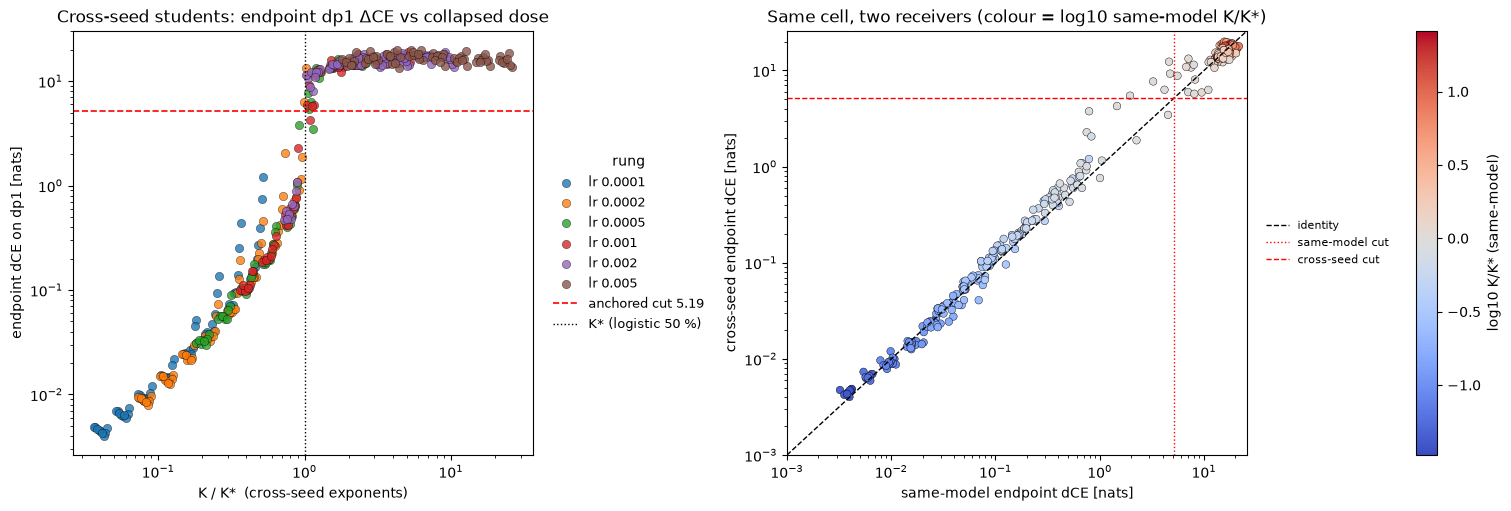

both-alive cells (n=224): median dCE cross/same = 1.11, Pearson r of log dCE = 0.991


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ax = axes[0]
pal = aplots.palette(sorted(df["lr"].unique()), cmap="tab10")
for lr, sub in df.dropna(subset=["delta_ce"]).groupby("lr"):
    ax.scatter(sub["K_rel"], sub["delta_ce"].clip(lower=1e-3), s=36, alpha=0.8,
               color=pal[lr], label=f"lr {lr:g}", edgecolor="k", linewidth=0.3)
ax.axhline(CUT["cross-seed 2"], ls="--", color="red", lw=1.2, label=f"anchored cut {CUT['cross-seed 2']:.2f}")
ax.axvline(1.0, ls=":", color="k", lw=1.0, label="K* (logistic 50 %)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("K / K*  (cross-seed exponents)"); ax.set_ylabel("endpoint dCE on dp1 [nats]")
ax.set_title("Cross-seed students: endpoint dp1 ΔCE vs collapsed dose")
aplots.right_legend(ax, title="rung")
ax = axes[1]
sc = ax.scatter(both["delta_ce_s"].clip(lower=1e-3), both["delta_ce_x"].clip(lower=1e-3), s=30,
                c=np.log10(both["tag"].map(df_same.set_index("tag")["K_rel"])), cmap="coolwarm",
                edgecolor="k", linewidth=0.3)
lim = (1e-3, float(max(both["delta_ce_s"].max(), both["delta_ce_x"].max())) * 1.2)
ax.plot(lim, lim, color="k", lw=1, ls="--", label="identity")
ax.axvline(CUT["same-model"], color="red", ls=":", lw=1, label="same-model cut")
ax.axhline(CUT["cross-seed 2"], color="red", ls="--", lw=1, label="cross-seed cut")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("same-model endpoint dCE [nats]"); ax.set_ylabel("cross-seed endpoint dCE [nats]")
ax.set_title("Same cell, two receivers (colour = log10 same-model K/K*)")
fig.colorbar(sc, ax=ax, label="log10 K/K* (same-model)")
aplots.right_legend(ax, fontsize=8)
plt.show()
alive_both = both[both["fate"] == "both alive"]
r = np.corrcoef(np.log(alive_both["delta_ce_s"].clip(lower=1e-3)), np.log(alive_both["delta_ce_x"].clip(lower=1e-3)))[0, 1]
print(f"both-alive cells (n={len(alive_both)}): median dCE cross/same = "
      f"{(alive_both['delta_ce_x'] / alive_both['delta_ce_s']).median():.2f}, Pearson r of log dCE = {r:.3f}")

## 3. Transfer at the endpoint

Row unit: one run.  `p_test` is the endpoint probability mass on " elephant" over the 50 `test`
prompts; each arm's base prior is its own base-control value (§1).  Tables restrict to **alive**
runs (endpoint ΔCE ≤ that arm's cut) unless the row says otherwise.

### 3a. Distribution, cross-seed vs same-model

endpoint p_test over alive runs, per arm (row unit: arm; columns: quantiles of the alive runs):


,n alive,base prior,mean,q05,q25,q50,q75,q95,max,median / prior,frac > 2x prior,frac > 0.10,frac > 0.20,peak median,peak median / prior
cross-seed 2,224.0,0.0287,0.0424,0.0125,0.0356,0.0422,0.0501,0.0686,0.1296,1.4689,0.1161,0.0045,0.0000,0.0538,1.8725
same-model,229.0,0.0231,0.1126,0.0352,0.0735,0.0954,0.1180,0.2399,0.6019,4.1330,0.9127,0.4629,0.0873,0.3771,16.3333


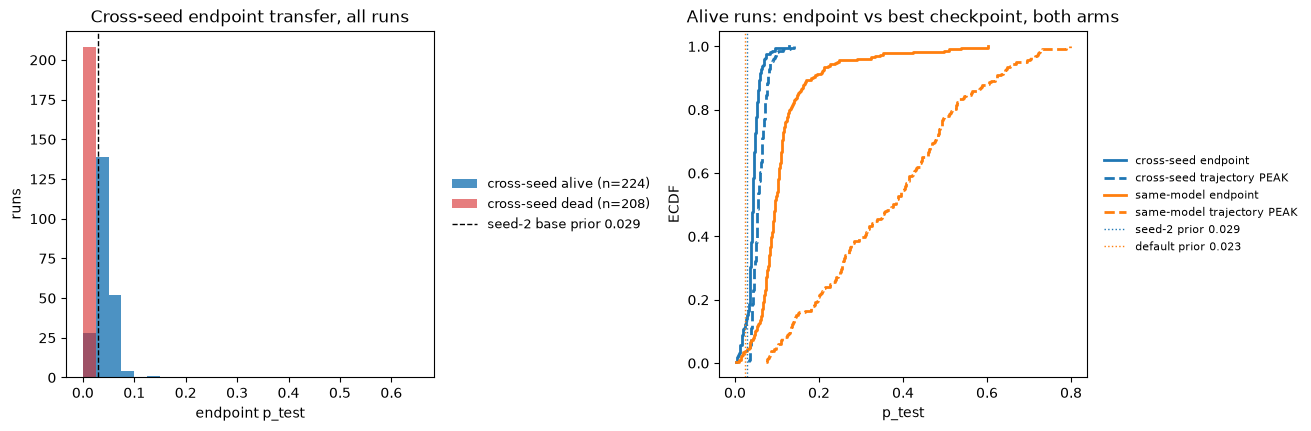

In [5]:
ALIVE = {arm: f[f["collapsed"] == False].copy() for arm, f in FR.items()}   # noqa: E712
DEAD = {arm: f[f["collapsed"] == True].copy() for arm, f in FR.items()}     # noqa: E712
alive, dead = ALIVE["cross-seed 2"], DEAD["cross-seed 2"]
p0 = PRIOR["cross-seed 2"]["test"]; p0_s = PRIOR["same-model"]["test"]

def _summ(a, p):
    q = a["p_test"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).rename(lambda x: f"q{int(x*100):02d}")
    return pd.Series({"n alive": len(a), "base prior": p, "mean": a["p_test"].mean(), **q.to_dict(),
                      "max": a["p_test"].max(), "median / prior": a["p_test"].median() / p,
                      "frac > 2x prior": (a["p_test"] > 2 * p).mean(),
                      "frac > 0.10": (a["p_test"] > 0.10).mean(), "frac > 0.20": (a["p_test"] > 0.20).mean(),
                      "peak median": a["p_test_peak"].median(), "peak median / prior": a["p_test_peak"].median() / p})
summary = pd.DataFrame({arm: _summ(ALIVE[arm], PRIOR[arm]["test"]) for arm in ARMS}).T
print("endpoint p_test over alive runs, per arm (row unit: arm; columns: quantiles of the alive runs):")
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
ax = axes[0]
bins = np.linspace(0, 0.65, 27)
ax.hist(alive["p_test"], bins=bins, color="tab:blue", alpha=0.8, label=f"cross-seed alive (n={len(alive)})")
ax.hist(dead["p_test"], bins=bins, color="tab:red", alpha=0.6, label=f"cross-seed dead (n={len(dead)})")
ax.axvline(p0, color="k", ls="--", lw=1, label=f"seed-2 base prior {p0:.3f}")
ax.set_xlabel("endpoint p_test"); ax.set_ylabel("runs"); ax.set_title("Cross-seed endpoint transfer, all runs")
aplots.right_legend(ax)
ax = axes[1]
aplots.ecdf_plot(ax, alive["p_test"], label="cross-seed endpoint", color="tab:blue", lw=2)
aplots.ecdf_plot(ax, alive["p_test_peak"], label="cross-seed trajectory PEAK", color="tab:blue", lw=2, ls="--")
aplots.ecdf_plot(ax, ALIVE["same-model"]["p_test"], label="same-model endpoint", color="tab:orange", lw=2)
aplots.ecdf_plot(ax, ALIVE["same-model"]["p_test_peak"], label="same-model trajectory PEAK", color="tab:orange", lw=2, ls="--")
ax.axvline(p0, color="tab:blue", ls=":", lw=1, label=f"seed-2 prior {p0:.3f}")
ax.axvline(p0_s, color="tab:orange", ls=":", lw=1, label=f"default prior {p0_s:.3f}")
ax.set_xlabel("p_test"); ax.set_ylabel("ECDF"); ax.set_title("Alive runs: endpoint vs best checkpoint, both arms")
aplots.right_legend(ax, fontsize=8)
plt.show()

### 3b. Endpoint transfer by hyper-parameter

Aggregation: median (and max) of endpoint `p_test` over the alive cross-seed runs sharing the row
value; `same-model median` is the same statistic in the comparator arm.

by lr rung (alive cross-seed runs):


,n,median,mean,max,peak median,n dead,same-model median,same-model peak median
lr,,,,,,,,
0.0001,72,0.041,0.043,0.074,0.048,0,0.094,0.233
0.0002,69,0.042,0.042,0.088,0.052,3,0.088,0.311
0.0005,46,0.045,0.046,0.130,0.063,26,0.106,0.415
0.0010,28,0.035,0.035,0.096,0.064,44,0.112,0.521
0.0020,9,0.036,0.042,0.095,0.052,63,0.135,0.637


by rank (alive cross-seed runs):


,n,median,mean,max,peak median,n dead,same-model median,same-model peak median
rank,,,,,,,,
1,24,0.040,0.040,0.130,0.053,24,0.198,0.408
2,24,0.039,0.041,0.069,0.052,24,0.090,0.308
4,24,0.044,0.044,0.088,0.053,24,0.108,0.380
8,25,0.044,0.041,0.095,0.054,23,0.092,0.405
16,25,0.042,0.045,0.074,0.054,23,0.094,0.407
32,26,0.040,0.041,0.075,0.061,22,0.088,0.356
64,26,0.042,0.044,0.096,0.054,22,0.083,0.355
128,25,0.044,0.045,0.073,0.054,23,0.091,0.387
256,25,0.042,0.041,0.060,0.054,23,0.100,0.361


by alpha (alive cross-seed runs):


,n,median,mean,max,peak median,n dead,same-model median,same-model peak median
alpha,,,,,,,,
4,45,0.039,0.041,0.095,0.051,9,0.106,0.259
8,36,0.040,0.042,0.096,0.046,18,0.091,0.276
16,36,0.040,0.038,0.073,0.050,18,0.100,0.309
32,28,0.043,0.049,0.130,0.055,26,0.098,0.311
64,27,0.046,0.046,0.069,0.057,27,0.103,0.387
128,19,0.049,0.049,0.088,0.065,35,0.090,0.381
256,18,0.049,0.042,0.057,0.069,36,0.108,0.469
512,15,0.031,0.035,0.074,0.059,39,0.050,0.492


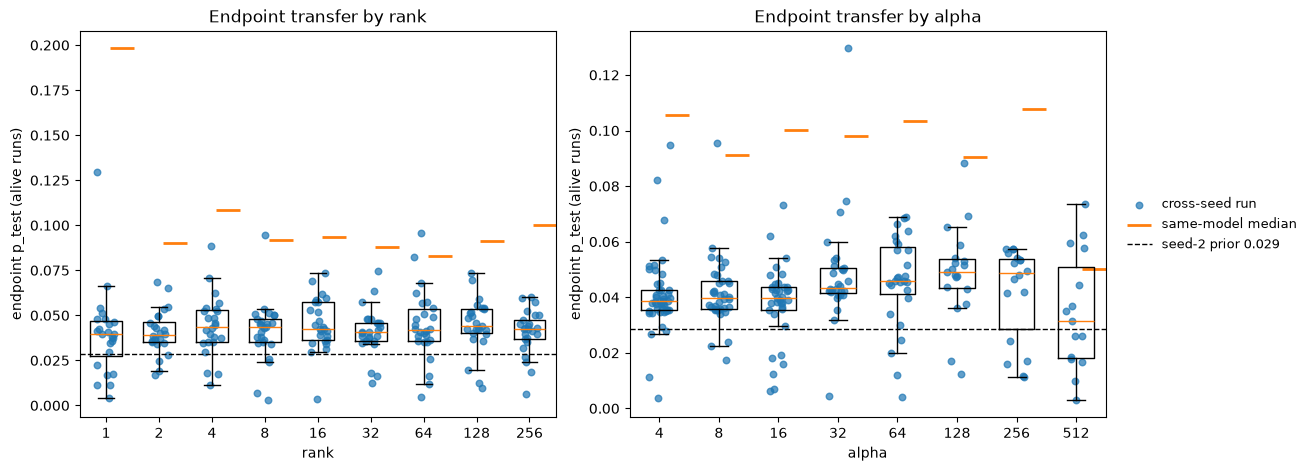

In [6]:
def _by(col):
    t = alive.groupby(col)["p_test"].agg(n="size", median="median", mean="mean", max="max")
    t["peak median"] = alive.groupby(col)["p_test_peak"].median()
    t["n dead"] = dead.groupby(col).size().reindex(t.index).fillna(0).astype(int)
    t["same-model median"] = ALIVE["same-model"].groupby(col)["p_test"].median().reindex(t.index)
    t["same-model peak median"] = ALIVE["same-model"].groupby(col)["p_test_peak"].median().reindex(t.index)
    return t.round(3)

print("by lr rung (alive cross-seed runs):"); display(_by("lr"))
print("by rank (alive cross-seed runs):"); display(_by("rank"))
print("by alpha (alive cross-seed runs):"); display(_by("alpha"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
for ax, col in zip(axes, ["rank", "alpha"]):
    vals = sorted(alive[col].unique())
    data = [alive.loc[alive[col] == v, "p_test"].to_numpy() for v in vals]
    ax.boxplot(data, positions=range(len(vals)), widths=0.6, showfliers=False)
    for i, v in enumerate(vals):
        y = alive.loc[alive[col] == v, "p_test"]
        ax.scatter(i + aplots.jitter(len(y), 0.18, seed=i), y, s=22, alpha=0.7, color="tab:blue",
                   label="cross-seed run" if i == 0 else None)
        ys = ALIVE["same-model"].loc[ALIVE["same-model"][col] == v, "p_test"]
        ax.scatter([i + 0.3], [ys.median()], marker="_", s=300, color="tab:orange", lw=2,
                   label="same-model median" if i == 0 else None)
    ax.axhline(p0, color="k", ls="--", lw=1, label=f"seed-2 prior {p0:.3f}")
    ax.set_xticks(range(len(vals))); ax.set_xticklabels([f"{v:g}" for v in vals])
    ax.set_xlabel(col); ax.set_ylabel("endpoint p_test (alive runs)"); ax.set_title(f"Endpoint transfer by {col}")
aplots.right_legend(axes[1])
plt.show()

### 3c. Endpoint and peak transfer against K/K*

Both arms on the **same-model** K axis (same-model exponents and K*, so a cell sits at the same x
in both panels); colour = rank.  Left endpoint, right trajectory peak.  Below: alive cross-seed
runs binned on log10(K/K*) (own exponents), endpoint vs peak medians per bin.

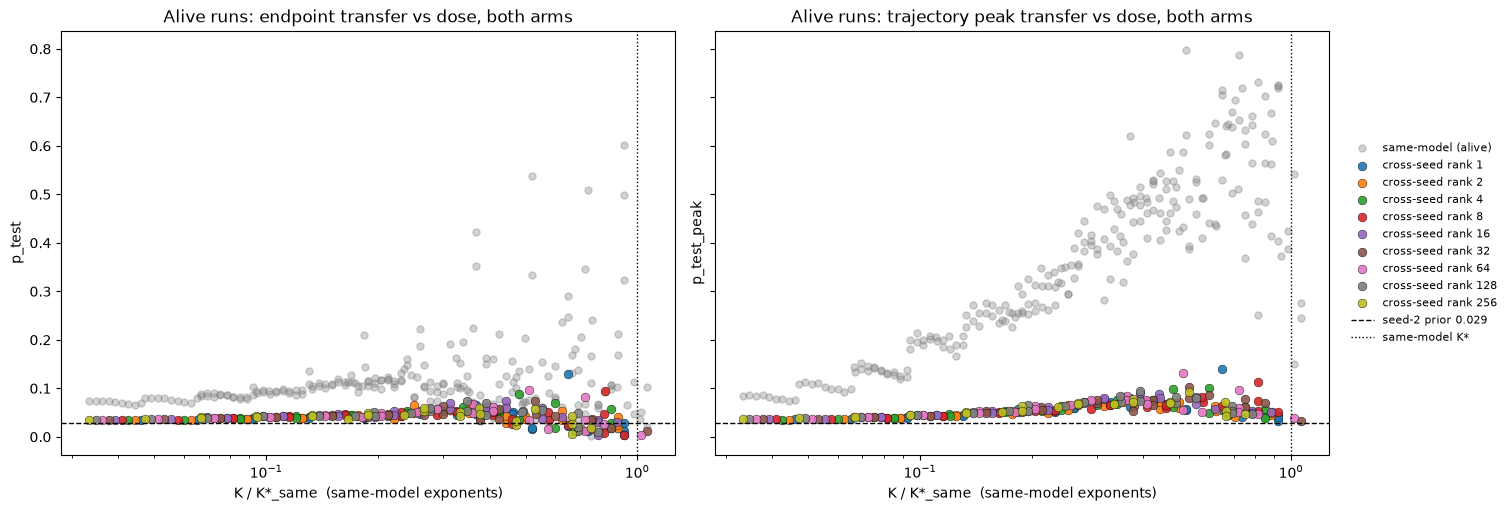

alive cross-seed runs binned on log10(K/K*) (cross-seed exponents): endpoint vs trajectory peak (median over the bin)


,n,end_median,end_max,peak_median,peak_max,peak_step_median,dce_median
K bin (log10 K/K*),,,,,,,
"(-1.5, -1.0]",36,0.037,0.040,0.038,0.042,5616.0,0.008
"(-1.0, -0.75]",34,0.042,0.048,0.046,0.054,5000.0,0.020
"(-0.75, -0.5]",43,0.048,0.065,0.060,0.076,4056.0,0.041
"(-0.5, -0.25]",57,0.051,0.096,0.072,0.131,4375.0,0.134
"(-0.25, 0.0]",52,0.029,0.130,0.053,0.140,2186.0,0.512
"(0.0, 0.5]",2,0.008,0.012,0.035,0.038,625.0,3.855


In [7]:
pal_r = aplots.palette(RANKS, cmap="tab10")
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True, sharey=True)
for ax, col, title in [(axes[0], "p_test", "endpoint"), (axes[1], "p_test_peak", "trajectory peak")]:
    a_s = ALIVE["same-model"]
    ax.scatter(a_s["K_rel"], a_s[col], s=26, alpha=0.35, color="gray", label="same-model (alive)")
    for r, sub in alive.groupby("rank"):
        ax.scatter(sub["K_rel_same_axis"], sub[col], s=40, alpha=0.9, color=pal_r[r], label=f"cross-seed rank {r}",
                   edgecolor="k", linewidth=0.3)
    ax.axhline(p0, color="k", ls="--", lw=1, label=f"seed-2 prior {p0:.3f}")
    ax.axvline(1.0, ls=":", color="k", lw=1, label="same-model K*")
    ax.set_xscale("log"); ax.set_xlabel("K / K*_same  (same-model exponents)"); ax.set_ylabel(col)
    ax.set_title(f"Alive runs: {title} transfer vs dose, both arms")
aplots.right_legend(axes[1], fontsize=8)
plt.show()

bins = [-3, -1.5, -1, -0.75, -0.5, -0.25, 0, 0.5]
alive["K bin (log10 K/K*)"] = pd.cut(alive["log10_K_rel"], bins)
t = alive.groupby("K bin (log10 K/K*)", observed=True).agg(
    n=("p_test", "size"), end_median=("p_test", "median"), end_max=("p_test", "max"),
    peak_median=("p_test_peak", "median"), peak_max=("p_test_peak", "max"),
    peak_step_median=("p_test_peak_step", "median"), dce_median=("delta_ce", "median")).round(3)
print("alive cross-seed runs binned on log10(K/K*) (cross-seed exponents): endpoint vs trajectory peak (median over the bin)")
display(t)

## 4. Transfer on the (rank, alpha) grid — endpoint, trajectory peak, and fixed step counts

Same recipe as `transfer_trajectory_grids.ipynb` §2: population = **endpoint-alive** runs of
the arm; one cell per (rank, alpha) holding the median `p_test` over that cell's alive lr rungs
(`n` = alive rungs, 0–6).  Top row: endpoint and best checkpoint.  Bottom row: each run's saved
checkpoint nearest step 625, 1,250, 2,500, 5,000, 10,000 (of 12,500; the panel title names the
median checkpoint actually used — the cross-seed arm mixes 312- and 625-step cadences).  All
panels of one figure share a colour scale (0 to that arm's largest peak median); the same-model
figure follows for comparison, on its own scale.  Absolute steps only, never a share of the run.

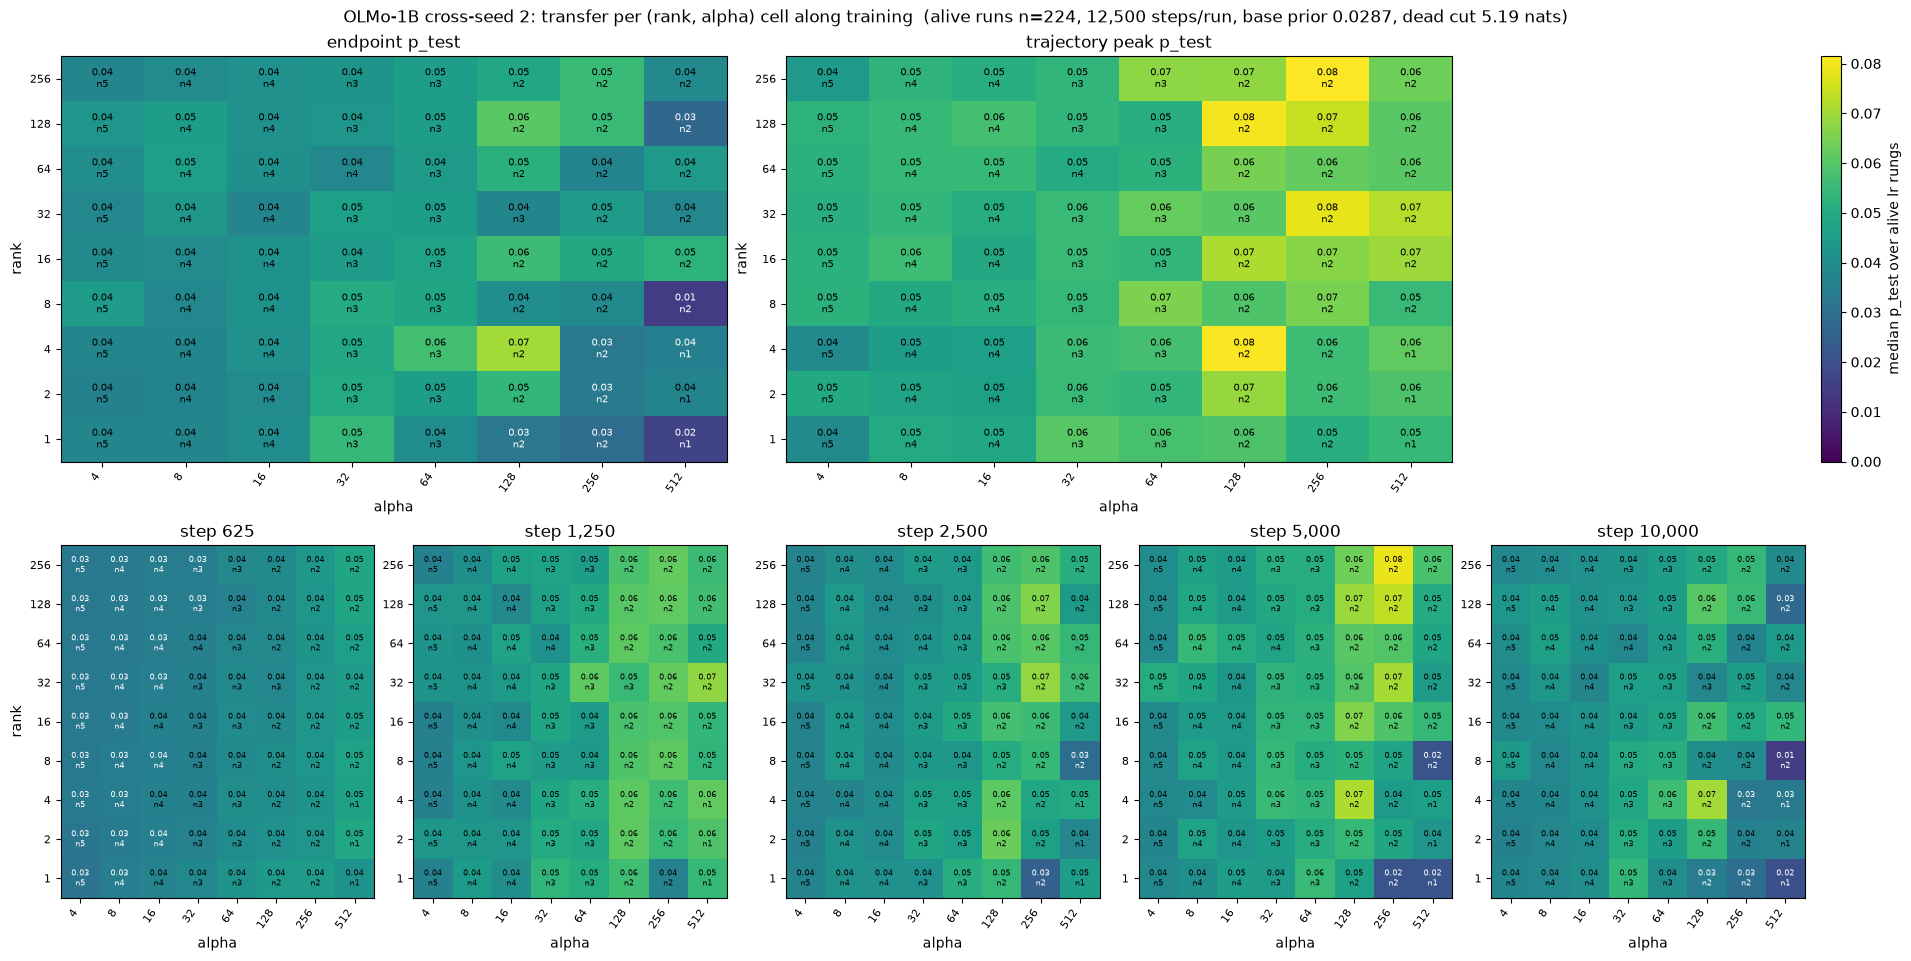

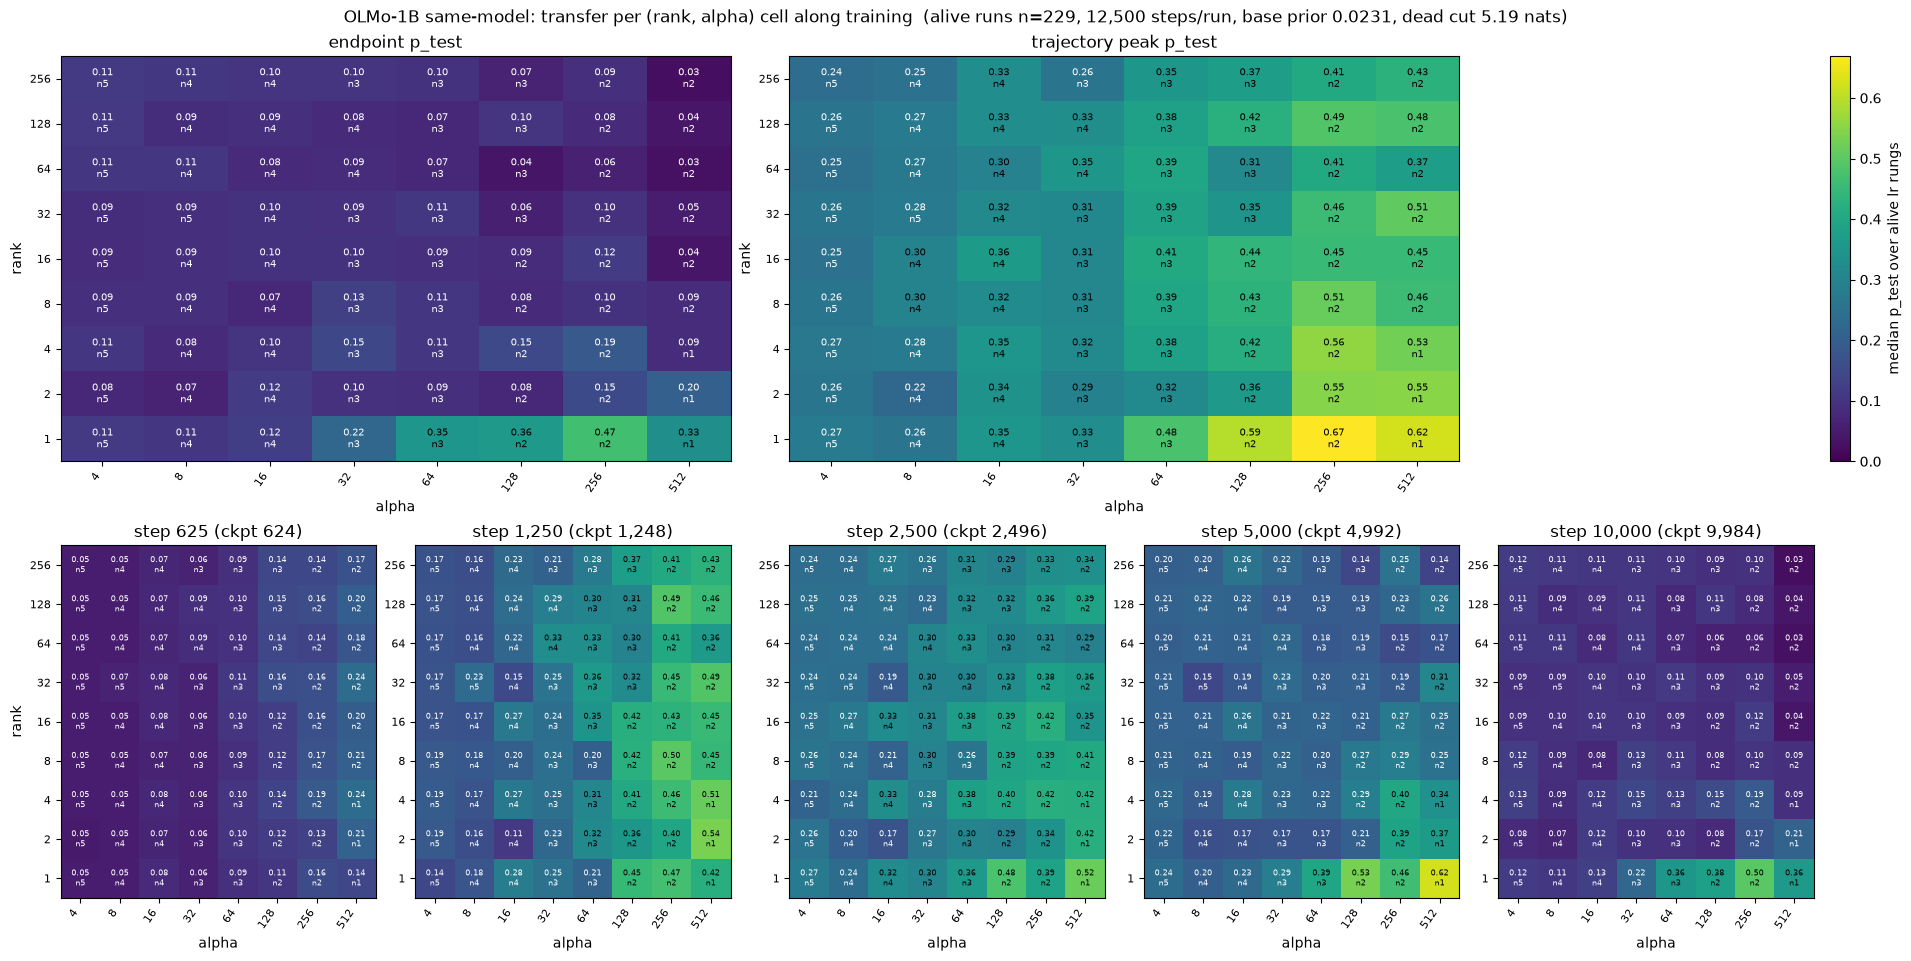

In [8]:
def _grid(sub, col):
    g = sub.pivot_table(index="rank", columns="alpha", values=col, aggfunc="median").reindex(index=RANKS, columns=ALPHAS)
    n = sub.pivot_table(index="rank", columns="alpha", values=col, aggfunc="size").reindex(index=RANKS, columns=ALPHAS)
    return g, n

def _at_step(tr, alive_tags, step):
    """Per run, the saved checkpoint nearest `step` (within 10 %); grid of p_test over those."""
    t = tr[tr["tag"].isin(alive_tags) & tr["p_test"].notna()].copy()
    t["d"] = (t["step"] - step).abs()
    pick = t.loc[t.groupby("tag")["d"].idxmin()]
    pick = pick[pick["d"] <= 0.1 * step]
    if pick.empty:
        return None, None
    return _grid(pick, "p_test"), int(pick["step"].median())

def arm_panels(arm):
    end, tr = FR[arm], TR[arm]
    a = ALIVE[arm]; alive_tags = set(a["tag"])
    views = {"endpoint": _grid(a, "p_test"), "trajectory peak": _grid(a, "p_test_peak")}
    at_step = {st: _at_step(tr, alive_tags, st) for st in STEPS}
    vmax = float(np.nanmax(views["trajectory peak"][0].to_numpy()))
    fig = plt.figure(figsize=(19, 9.5), constrained_layout=True)
    gs = fig.add_gridspec(2, 5, height_ratios=[1.15, 1])
    for j, (name, (g, n)) in enumerate(views.items()):
        ax = fig.add_subplot(gs[0, 2 * j:2 * j + 2])
        im = aplots.annotated_heatmap(ax, g, counts=n, cmap="viridis", vmin=0, vmax=vmax, fmt="{:.2f}", cell_fontsize=7)
        ax.set_xlabel("alpha"); ax.set_ylabel("rank"); ax.set_title(f"{name} p_test")
    cax = fig.add_subplot(gs[0, 4]); cax.axis("off")
    fig.colorbar(im, ax=cax, fraction=0.5, label="median p_test over alive lr rungs")
    for j, st in enumerate(STEPS):
        gn, got = at_step[st]
        ax = fig.add_subplot(gs[1, j])
        g, n = gn
        aplots.annotated_heatmap(ax, g, counts=n, cmap="viridis", vmin=0, vmax=vmax, fmt="{:.2f}", cell_fontsize=6)
        ax.set_xlabel("alpha"); ax.set_ylabel("rank" if j == 0 else "")
        ax.set_title(f"step {st:,}" + ("" if got == st else f" (ckpt {got:,})"))
    fig.suptitle(f"OLMo-1B {arm}: transfer per (rank, alpha) cell along training  "
                 f"(alive runs n={len(a)}, {int(end['n_train_steps'].median()):,} steps/run, "
                 f"base prior {PRIOR[arm]['test']:.4f}, dead cut {CUT[arm]:.2f} nats)")
    plt.show()
    return views, at_step

PANELS = {arm: arm_panels(arm) for arm in ARMS}

### 4b. Grid summary, both arms

Row unit: one arm.  `grid median` = median over the 72 cells of the cell medians (every
(rank, alpha) pair counts once).  `step N` = grid median at the checkpoint nearest step N;
`peak step (med)` = median over alive runs of the step of their best score; `peak/end (med)` =
median over alive runs of best/endpoint score.  Second table: the same in units of each arm's own
base prior.  Then the cell-wise ratio cross/same of the endpoint and peak grids.

In [9]:
def _gm(g, rows=None):
    v = g if rows is None else g.loc[rows]
    return float(np.nanmedian(v.to_numpy()))

rows = []
for arm in ARMS:
    a = ALIVE[arm]; views, at_step = PANELS[arm]
    r = {"arm": arm, "alive": len(a), "prior": round(PRIOR[arm]["test"], 4), "total steps": int(a["n_train_steps"].median())}
    for st in STEPS:
        gn, _ = at_step[st]
        r[f"step {st}"] = round(_gm(gn[0]), 3)
    r["endpoint"] = round(_gm(views["endpoint"][0]), 3)
    r["peak"] = round(_gm(views["trajectory peak"][0]), 3)
    r["peak step (med)"] = int(a["p_test_peak_step"].median())
    r["peak/end (med)"] = round(float((a["p_test_peak"] / a["p_test"].clip(lower=1e-6)).median()), 2)
    r["rank-1 end"] = round(_gm(views["endpoint"][0], [1]), 3)
    r["other end"] = round(_gm(views["endpoint"][0], [x for x in RANKS if x != 1]), 3)
    r["rank-1 peak"] = round(_gm(views["trajectory peak"][0], [1]), 3)
    r["other peak"] = round(_gm(views["trajectory peak"][0], [x for x in RANKS if x != 1]), 3)
    rows.append(r)
SUMMARY = pd.DataFrame(rows).set_index("arm")
display(SUMMARY)
rel = SUMMARY.copy()
REL_COLS = [f"step {st}" for st in STEPS] + ["endpoint", "peak", "rank-1 end", "other end", "rank-1 peak", "other peak"]
for c in REL_COLS:
    rel[c] = (SUMMARY[c] / SUMMARY["prior"]).round(1)
print("same table in units of each arm's base prior (x prior):")
display(rel.drop(columns=["prior", "peak step (med)", "peak/end (med)"]))

gx, gs_ = PANELS["cross-seed 2"][0], PANELS["same-model"][0]
ratio_end = (gx["endpoint"][0] / gs_["endpoint"][0]).round(2)
ratio_peak = (gx["trajectory peak"][0] / gs_["trajectory peak"][0]).round(2)
print("cell-wise ratio cross-seed / same-model of the ENDPOINT cell medians (rank x alpha; NaN = a cell alive in only one arm):")
display(ratio_end)
print("cell-wise ratio cross-seed / same-model of the PEAK cell medians:")
display(ratio_peak)
print(f"median over cells: endpoint ratio {np.nanmedian(ratio_end.to_numpy()):.2f}, peak ratio {np.nanmedian(ratio_peak.to_numpy()):.2f}")

,alive,prior,total steps,step 625,step 1250,step 2500,step 5000,step 10000,endpoint,peak,peak step (med),peak/end (med),rank-1 end,other end,rank-1 peak,other peak
arm,,,,,,,,,,,,,,,,
cross-seed 2,224,0.0287,12500,0.037,0.048,0.044,0.048,0.041,0.041,0.055,4375,1.25,0.037,0.042,0.053,0.055
same-model,229,0.0231,12500,0.091,0.278,0.302,0.212,0.101,0.095,0.352,3120,2.81,0.278,0.094,0.414,0.350


same table in units of each arm's base prior (x prior):


,alive,total steps,step 625,step 1250,step 2500,step 5000,step 10000,endpoint,peak,rank-1 end,other end,rank-1 peak,other peak
arm,,,,,,,,,,,,,
cross-seed 2,224,12500,1.3,1.7,1.5,1.7,1.4,1.4,1.9,1.3,1.5,1.8,1.9
same-model,229,12500,3.9,12.0,13.1,9.2,4.4,4.1,15.2,12.0,4.1,17.9,15.2


cell-wise ratio cross-seed / same-model of the ENDPOINT cell medians (rank x alpha; NaN = a cell alive in only one arm):


alpha,4,8,16,32,64,128,256,512
rank,,,,,,,,
1,0.33,0.35,0.32,0.24,0.11,0.09,0.06,0.05
2,0.46,0.55,0.34,0.52,0.49,0.70,0.22,0.18
4,0.35,0.46,0.39,0.33,0.53,0.47,0.17,0.41
8,0.49,0.42,0.56,0.40,0.45,0.48,0.39,0.17
16,0.45,0.42,0.42,0.46,0.50,0.66,0.42,1.32
32,0.44,0.46,0.37,0.48,0.42,0.64,0.47,0.75
64,0.38,0.43,0.51,0.45,0.61,1.35,0.61,1.49
128,0.39,0.52,0.44,0.53,0.61,0.59,0.70,0.69
256,0.33,0.37,0.40,0.42,0.46,0.73,0.59,1.55


cell-wise ratio cross-seed / same-model of the PEAK cell medians:


alpha,4,8,16,32,64,128,256,512
rank,,,,,,,,
1,0.14,0.19,0.14,0.18,0.12,0.10,0.08,0.09
2,0.19,0.21,0.13,0.19,0.17,0.19,0.10,0.11
4,0.14,0.16,0.13,0.18,0.15,0.19,0.10,0.12
8,0.20,0.17,0.16,0.18,0.17,0.14,0.13,0.12
16,0.21,0.19,0.14,0.18,0.13,0.16,0.15,0.15
32,0.20,0.20,0.16,0.18,0.16,0.17,0.17,0.14
64,0.21,0.20,0.19,0.14,0.13,0.21,0.15,0.16
128,0.20,0.20,0.17,0.16,0.13,0.19,0.15,0.13
256,0.18,0.21,0.16,0.21,0.19,0.18,0.20,0.15


median over cells: endpoint ratio 0.45, peak ratio 0.16


### 4c. Grid-median trajectory, both arms

Left: grid median of the cell medians at each step target and at the endpoint, in units of the
arm's base prior; star = the arm's peak grid median at its median peak step.  Right: the
rank-1 vs other-rank split at endpoint and peak.

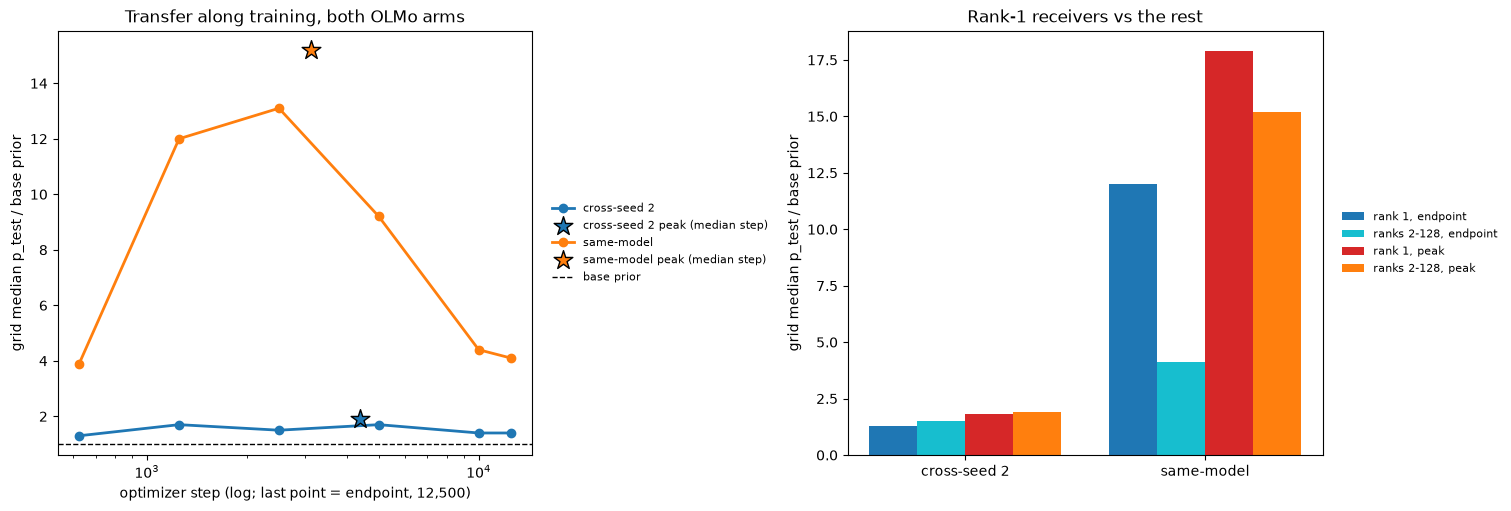

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
pal_a = {"cross-seed 2": "tab:blue", "same-model": "tab:orange"}
ax = axes[0]
for arm in ARMS:
    n_end = int(SUMMARY.loc[arm, "total steps"])
    pts = [(st, rel.loc[arm, f"step {st}"]) for st in STEPS] + [(n_end, rel.loc[arm, "endpoint"])]
    ax.plot([x for x, _ in pts], [y for _, y in pts], "o-", ms=6, lw=2, color=pal_a[arm], label=arm)
    ax.scatter([SUMMARY.loc[arm, "peak step (med)"]], [rel.loc[arm, "peak"]], marker="*", s=200,
               color=pal_a[arm], edgecolor="k", zorder=5, label=f"{arm} peak (median step)")
ax.axhline(1, color="k", ls="--", lw=1, label="base prior")
ax.set_xscale("log"); ax.set_xlabel("optimizer step (log; last point = endpoint, 12,500)")
ax.set_ylabel("grid median p_test / base prior"); ax.set_title("Transfer along training, both OLMo arms")
aplots.right_legend(ax, fontsize=8)
ax = axes[1]
w = 0.2; x0 = np.arange(len(ARMS))
for k, (col, lab) in enumerate([("rank-1 end", "rank 1, endpoint"), ("other end", "ranks 2-128, endpoint"),
                                ("rank-1 peak", "rank 1, peak"), ("other peak", "ranks 2-128, peak")]):
    ax.bar(x0 + (k - 1.5) * w, rel[col].to_numpy(), width=w, label=lab,
           color=["tab:blue", "tab:cyan", "tab:red", "tab:orange"][k])
ax.set_xticks(x0); ax.set_xticklabels(list(ARMS))
ax.set_ylabel("grid median p_test / base prior"); ax.set_title("Rank-1 receivers vs the rest")
aplots.right_legend(ax, fontsize=8)
plt.show()

### 4d. The 46-cell union arms (2026-09-07): orig→seed3, seed2→seed3, seed2→orig

Three further receiver/teacher pairings.  Their trees now hold **87 cells** each: the 46-cell
union below plus the 41-cell α=128 fill of §4e (2026-09-08); this section restricts to the
**46-cell union subset**: the union of the top-25
same-model cells and the top-25 cross-seed-2 cells by trajectory-peak `p_test` (only 4 shared;
list in `run_logs/dd1b/top25_union_cells.json`).  Teachers: the default-seed
`ep10_lr5e-4_r64a128` (orig→seed3) and its seed-2 twin (same recipe on `large-aux-2`,
dp1 ΔCE 3.61 vs 2.22 — a hotter teacher; seed2→seed3, seed2→orig).  Students ep10, ftseed 1,
saves every 625 steps.  Same heatmaps as §4: population = endpoint-alive runs of the arm, one
(rank, alpha) cell = median over that cell's alive lr rungs — here 0–3 rungs per cell, so most
of the grid is empty and single-rung cells are common (the `n` annotation is the read).  Each
figure has its own colour scale (0 to that arm's largest peak median).  The two full-band arms
(same-model, cross-seed 2; all 432 cells, no restriction to the 46) are re-plotted below them
and included in the summary table, so this section stands on its own.

coverage per arm (row unit: arm; the three new arms hold the 46 union cells, the two full-band arms all 432):


,orig→seed3,seed2→seed3,seed2→orig,same-model,cross-seed 2
cells,46.0000,46.0000,46.0000,432.0000,432.0000
alive,46.0000,46.0000,45.0000,229.0000,224.0000
both trajectories,46.0000,46.0000,46.0000,432.0000,432.0000
base prior,0.0179,0.0179,0.0231,0.0231,0.0287
dead cut,5.1790,5.1790,5.1860,5.1860,5.1890


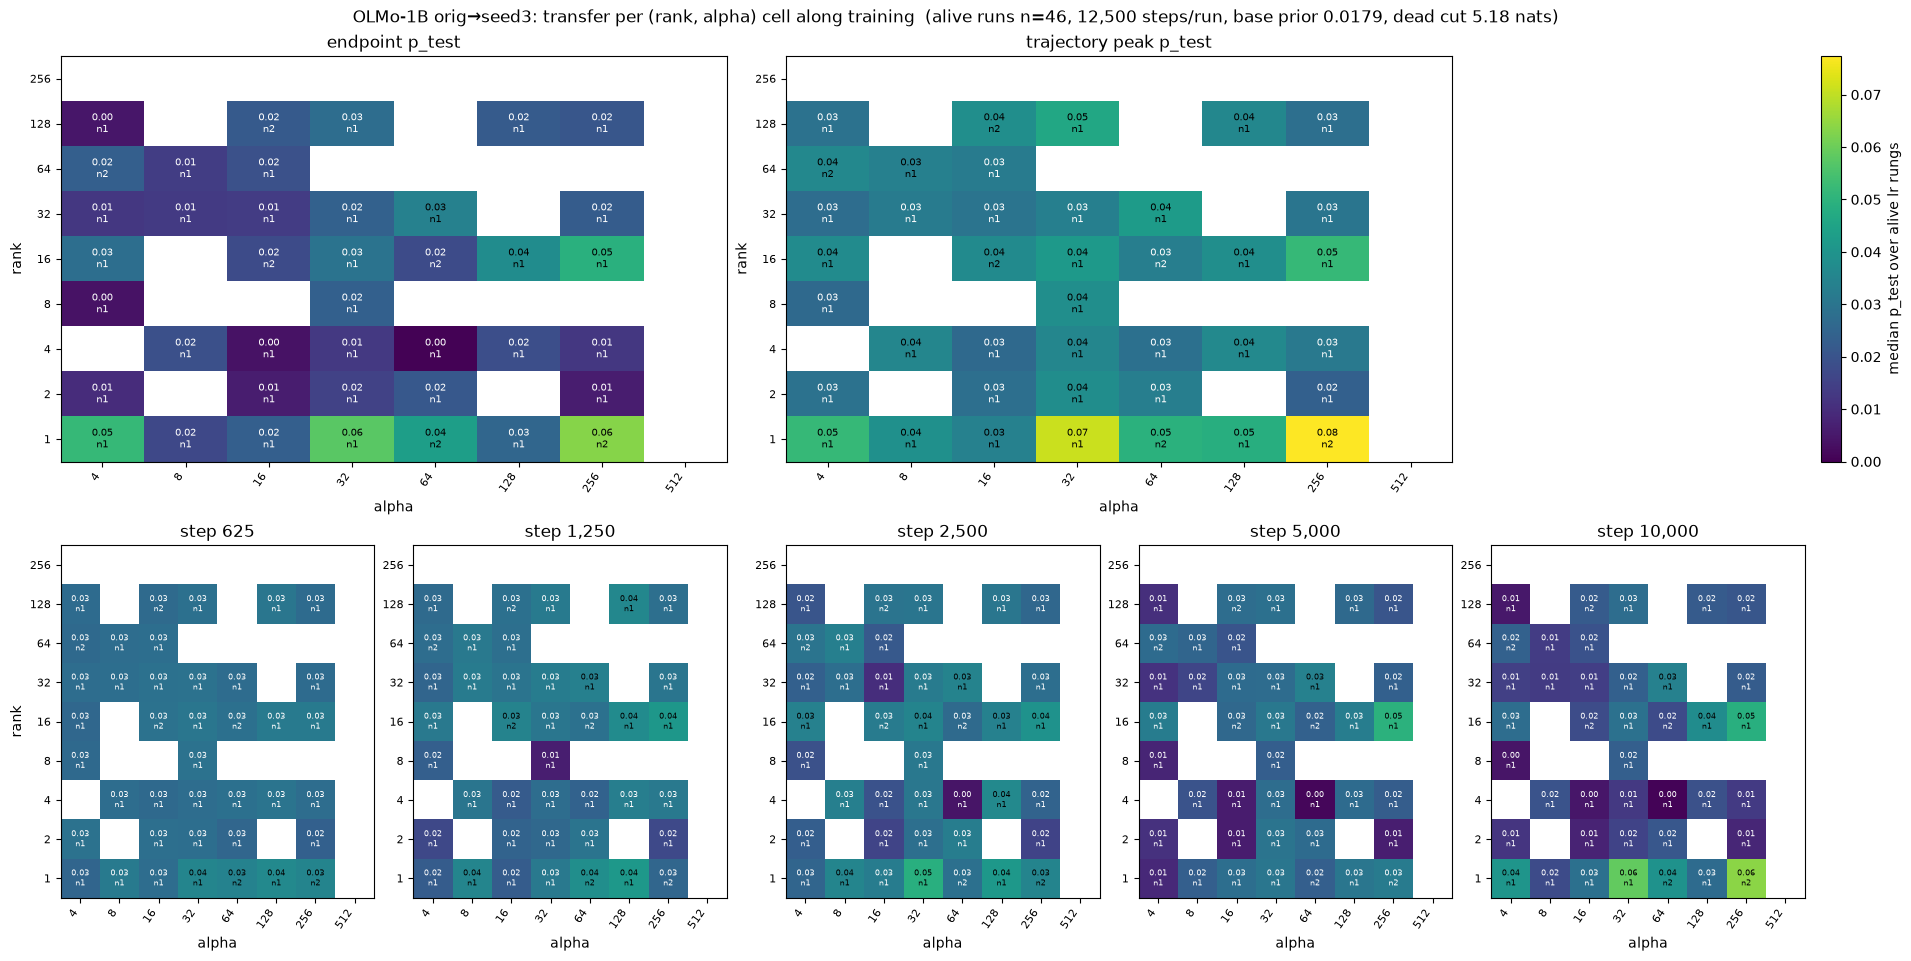

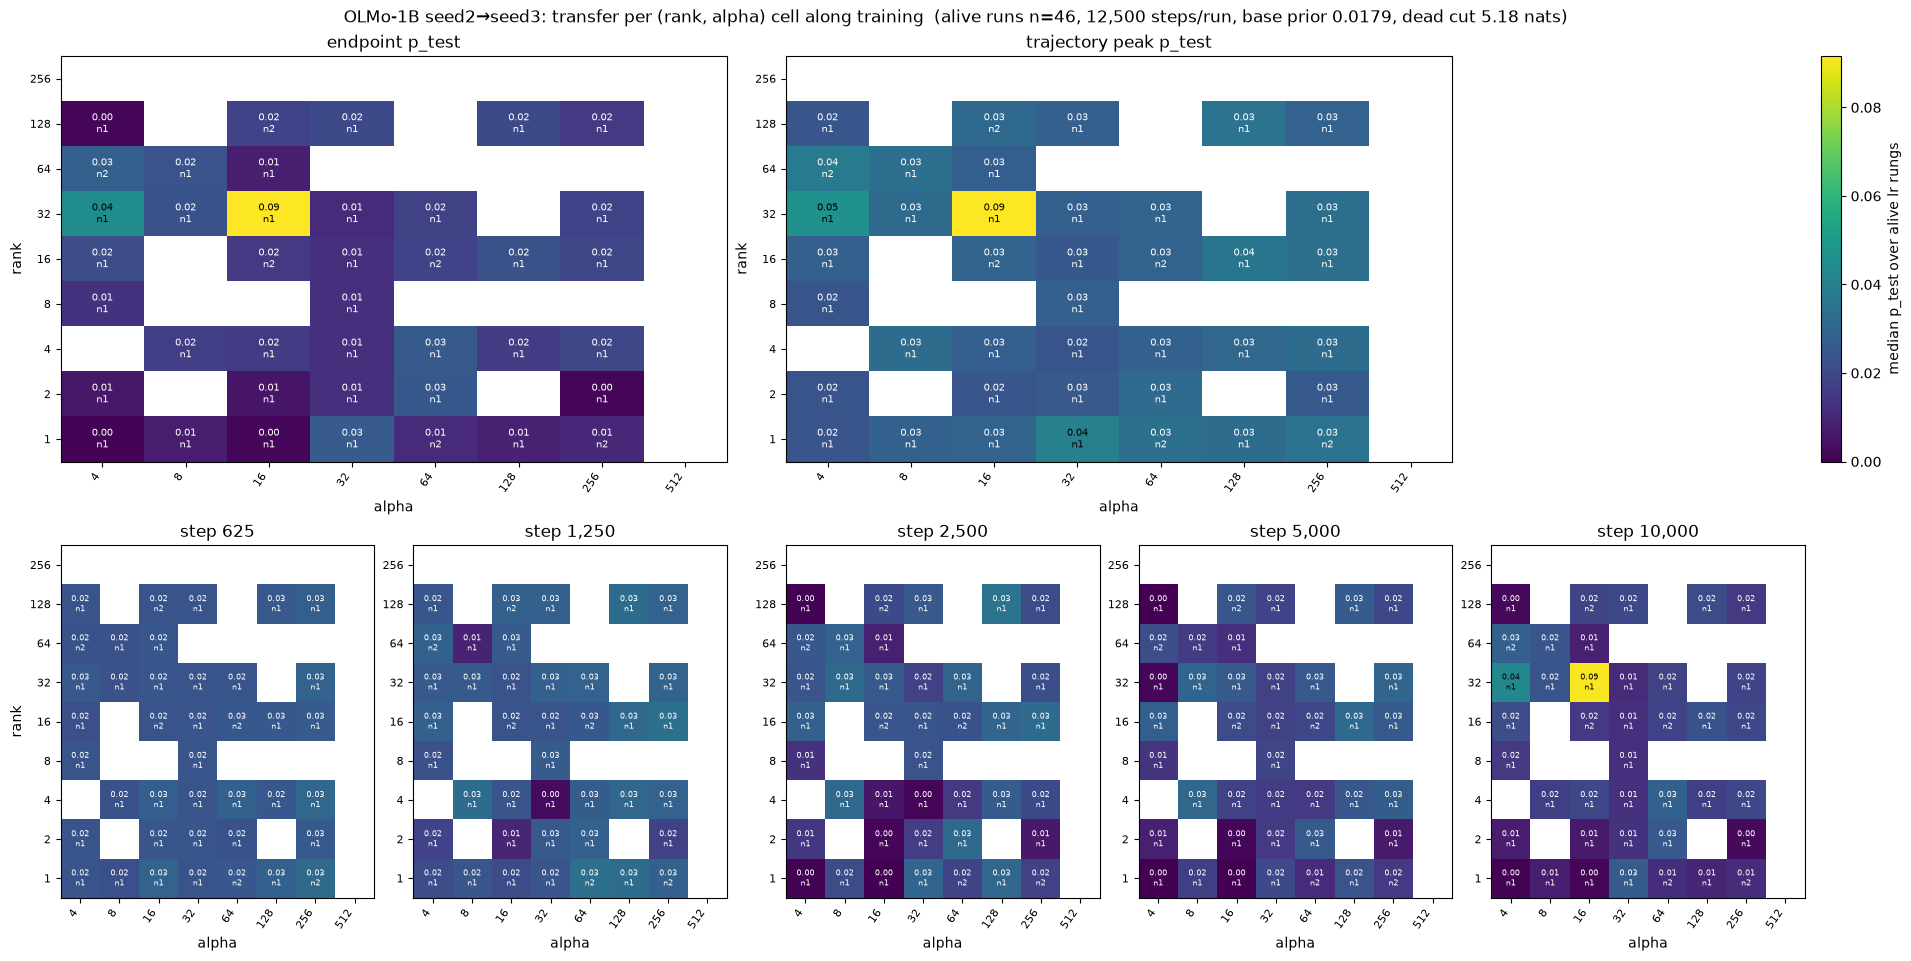

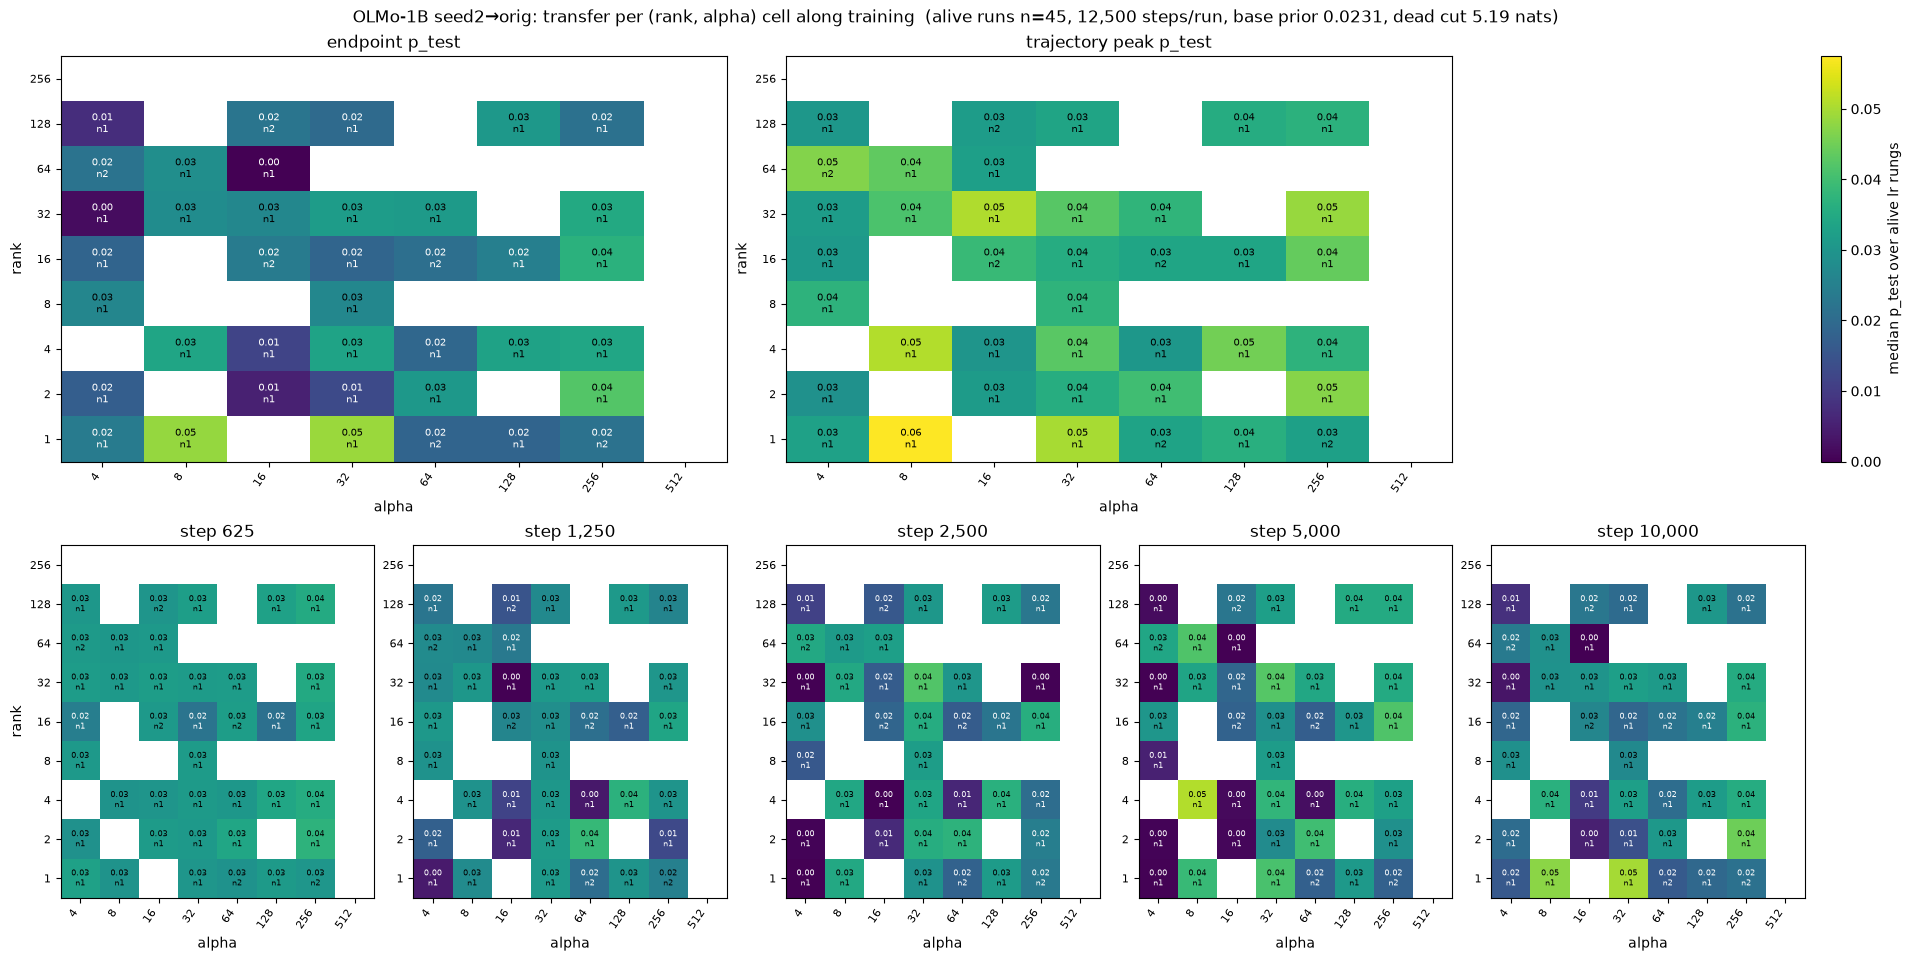

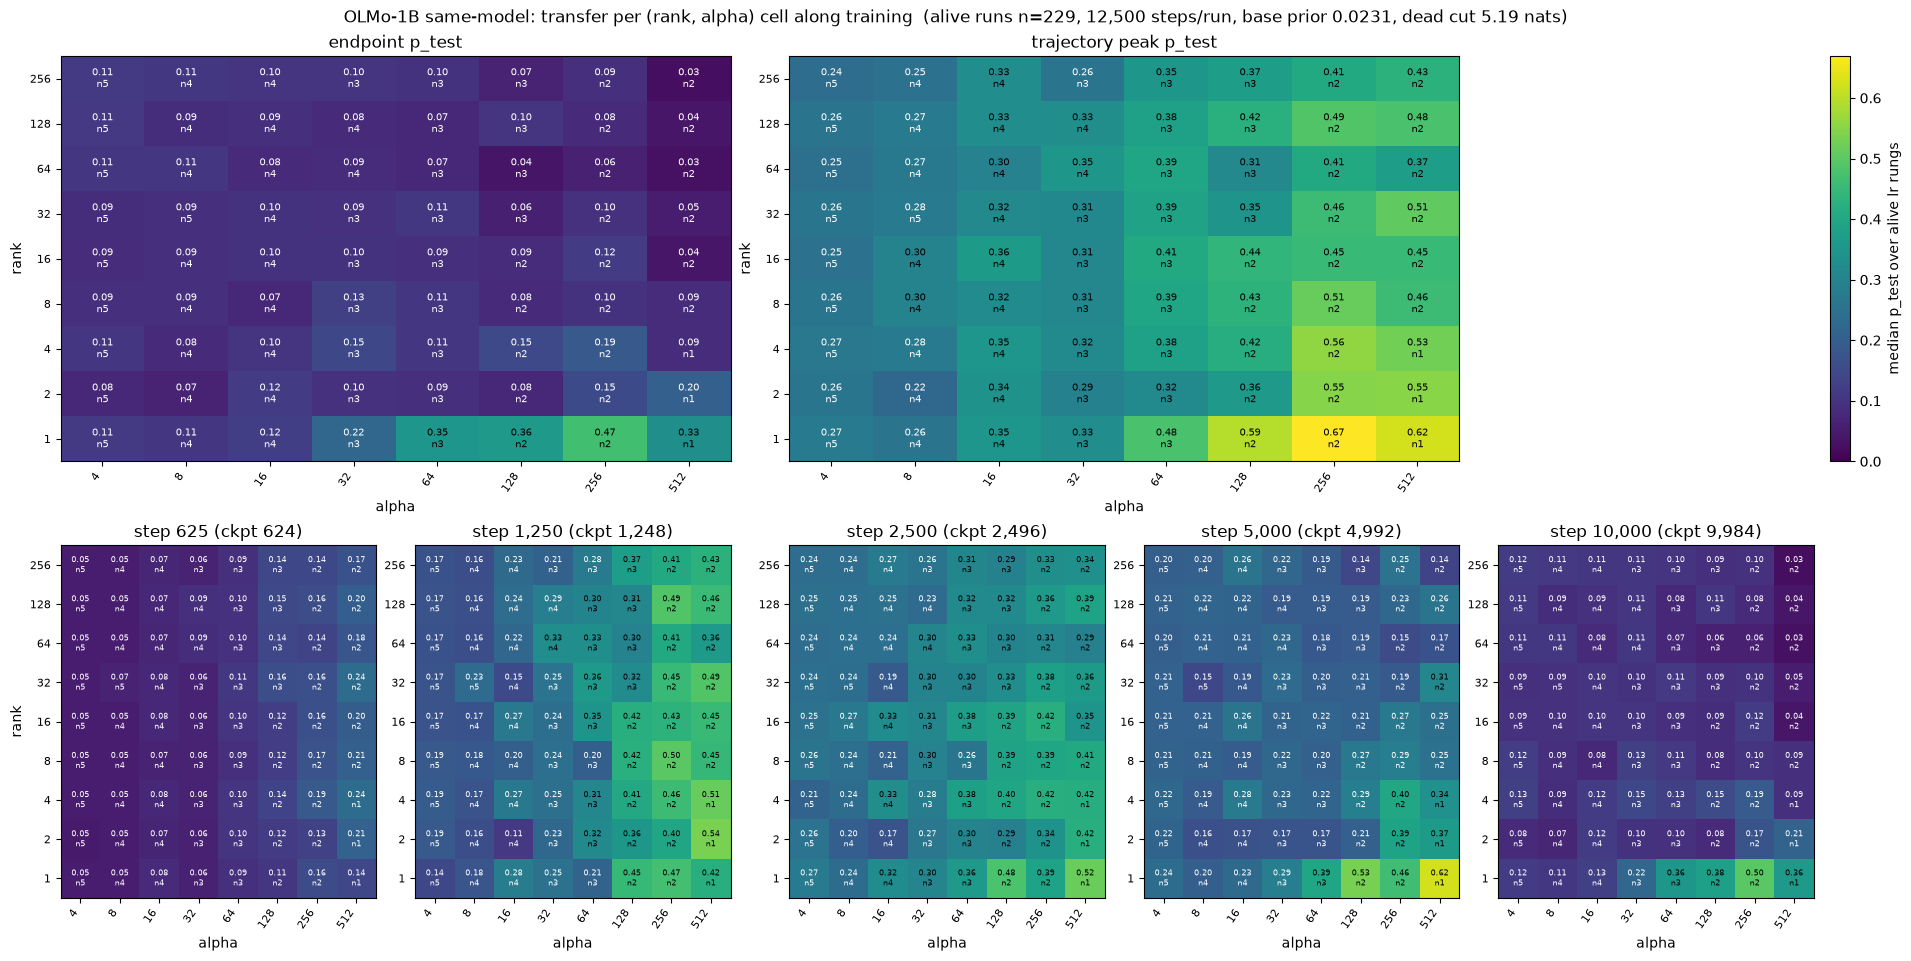

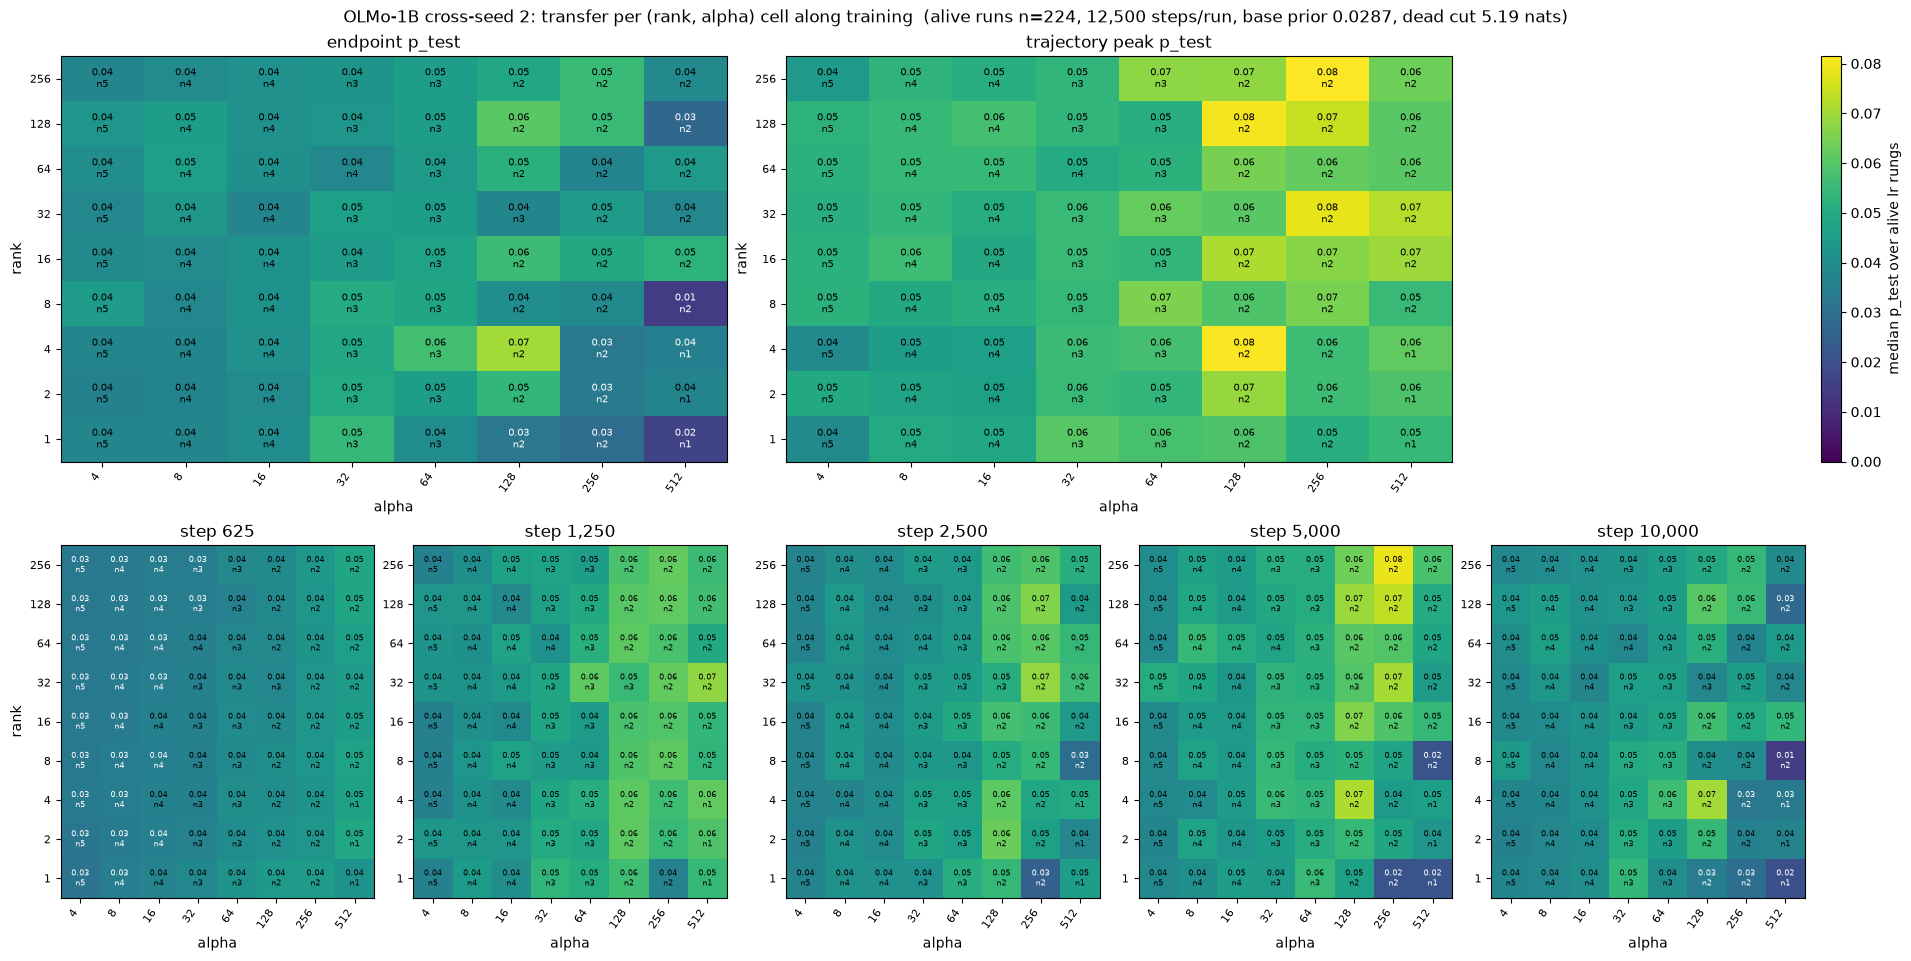

In [11]:
UNION = json.load(open("../run_logs/dd1b/top25_union_cells.json"))
UNION_TAGS = set(UNION["tags"])
NEW_ARMS = {   # arm -> loader kwargs (student base dir, teacher base dir)
    "orig→seed3": dict(base=dl.DD1B_SEED3_BASE, teacher_base=dl.DD1B_BASE),
    "seed2→seed3": dict(base=dl.DD1B_SEED3_BASE, teacher_base=dl.DD1B_SEED2_BASE),
    "seed2→orig": dict(base=dl.DD1B_BASE, teacher_base=dl.DD1B_SEED2_BASE),
}
for arm, kw in NEW_ARMS.items():
    CUT[arm] = labels.anchored_cut(OUTPUT_ROOT, kw["base"], pool="dp1")
    PRIOR[arm] = dl.load_base_prior(OUTPUT_ROOT, TEACHER, **kw)
    f = dl.load_endpoint_frame(OUTPUT_ROOT, TEACHER, seed=1, dead_cut=CUT[arm], **kw)
    f = f[f["tag"].isin(UNION_TAGS)].copy()
    f["collapsed"] = f["collapsed"].astype("boolean"); f["arm"] = arm
    FR[arm] = f
    t = dl.load_trajectories(OUTPUT_ROOT, TEACHER, seed=1, tags=sorted(UNION_TAGS), **kw)
    t["arm"] = arm
    TR[arm] = t
    ALIVE[arm] = f[f["collapsed"] == False].copy()   # noqa: E712
NEW = ["orig→seed3", "seed2→seed3", "seed2→orig"]
UNION_ARMS = NEW + ["same-model", "cross-seed 2"]   # the two full-band arms, ALL cells
# keep the union arms OUT of the section-wide dicts (later sections iterate ARMS/ALIVE): park them in
# their own dicts and lend them to `arm_panels` only while plotting.
FR46 = {arm: FR.pop(arm) for arm in NEW}; TR46 = {arm: TR.pop(arm) for arm in NEW}
ALIVE46 = {arm: ALIVE.pop(arm) for arm in NEW}
CUT46 = {arm: CUT.pop(arm) for arm in NEW}; PRIOR46 = {arm: PRIOR.pop(arm) for arm in NEW}
for arm in ("same-model", "cross-seed 2"):
    FR46[arm], TR46[arm], ALIVE46[arm], CUT46[arm], PRIOR46[arm] = FR[arm], TR[arm], ALIVE[arm], CUT[arm], PRIOR[arm]
cov46 = pd.DataFrame({arm: {
    "cells": len(FR46[arm]), "alive": len(ALIVE46[arm]), "both trajectories": int(FR46[arm]["has_traj"].sum()),
    "base prior": round(PRIOR46[arm]["test"], 4), "dead cut": round(CUT46[arm], 3),
} for arm in UNION_ARMS})
print("coverage per arm (row unit: arm; the three new arms hold the 46 union cells, the two full-band arms all 432):"); display(cov46)
PANELS46 = {}
for arm in NEW:
    FR[arm], TR[arm], ALIVE[arm], CUT[arm], PRIOR[arm] = FR46[arm], TR46[arm], ALIVE46[arm], CUT46[arm], PRIOR46[arm]
    try:
        PANELS46[arm] = arm_panels(arm)
    finally:
        for d in (FR, TR, ALIVE, CUT, PRIOR):
            d.pop(arm, None)
for arm in ("same-model", "cross-seed 2"):
    PANELS46[arm] = arm_panels(arm)

In [12]:
rows = []
for arm in UNION_ARMS:
    a = ALIVE46[arm]; views, at_step = PANELS46[arm]
    r = {"arm": arm, "alive": len(a), "prior": round(PRIOR46[arm]["test"], 4)}
    for st in STEPS:
        gn, _ = at_step[st]
        r[f"step {st}"] = round(_gm(gn[0]), 3) if gn is not None else np.nan
    r["endpoint"] = round(_gm(views["endpoint"][0]), 3)
    r["peak"] = round(_gm(views["trajectory peak"][0]), 3)
    r["peak step (med)"] = int(a["p_test_peak_step"].median())
    r["peak/end (med)"] = round(float((a["p_test_peak"] / a["p_test"].clip(lower=1e-6)).median()), 2)
    r["run-median end"] = round(float(a["p_test"].median()), 3)
    r["run-median peak"] = round(float(a["p_test_peak"].median()), 3)
    rows.append(r)
SUMMARY46 = pd.DataFrame(rows).set_index("arm")
print("union arms (46 cells) + full-band arms (432 cells) (row unit: arm; grid median = median over occupied (rank, alpha) cells of the cell medians;\n"
      "run-median = median over alive runs; steps are absolute optimizer steps of 12,500):")
display(SUMMARY46)
rel46 = SUMMARY46.copy()
for c in [f"step {st}" for st in STEPS] + ["endpoint", "peak", "run-median end", "run-median peak"]:
    rel46[c] = (SUMMARY46[c] / SUMMARY46["prior"]).round(1)
print("same table in units of each arm's own base prior (x prior):")
display(rel46.drop(columns=["prior", "peak step (med)", "peak/end (med)"]))

union arms (46 cells) + full-band arms (432 cells) (row unit: arm; grid median = median over occupied (rank, alpha) cells of the cell medians;
run-median = median over alive runs; steps are absolute optimizer steps of 12,500):


,alive,prior,step 625,step 1250,step 2500,step 5000,step 10000,endpoint,peak,peak step (med),peak/end (med),run-median end,run-median peak
arm,,,,,,,,,,,,,
orig→seed3,46,0.0179,0.028,0.030,0.030,0.026,0.020,0.020,0.036,4062,1.74,0.022,0.036
seed2→seed3,46,0.0179,0.024,0.026,0.022,0.019,0.017,0.016,0.029,1250,1.86,0.016,0.030
seed2→orig,45,0.0231,0.031,0.028,0.029,0.030,0.025,0.024,0.037,3750,1.49,0.024,0.036
same-model,229,0.0231,0.091,0.278,0.302,0.212,0.101,0.095,0.352,3120,2.81,0.095,0.377
cross-seed 2,224,0.0287,0.037,0.048,0.044,0.048,0.041,0.041,0.055,4375,1.25,0.042,0.054


same table in units of each arm's own base prior (x prior):


,alive,step 625,step 1250,step 2500,step 5000,step 10000,endpoint,peak,run-median end,run-median peak
arm,,,,,,,,,,
orig→seed3,46,1.6,1.7,1.7,1.5,1.1,1.1,2.0,1.2,2.0
seed2→seed3,46,1.3,1.5,1.2,1.1,0.9,0.9,1.6,0.9,1.7
seed2→orig,45,1.3,1.2,1.3,1.3,1.1,1.0,1.6,1.0,1.6
same-model,229,3.9,12.0,13.1,9.2,4.4,4.1,15.2,4.1,16.3
cross-seed 2,224,1.3,1.7,1.5,1.7,1.4,1.4,1.9,1.5,1.9


### 4e. The α=128 fill (2026-09-08): 41 cells per new arm, cell-matched against the full-band arms

The union of §4d was picked *by trajectory peak* in the same-model and cross-seed-2 arms, so on
those 46 cells the two full-band arms are winner's-curse inflated.  The fill adds an unselected
row: every (lr ∈ {1e-4, 2e-4, 5e-4}) × rank × **α=128** cell of the band that was not already in the
union and not known dead in either full-band arm — 41 cells (`run_logs/dd1b/highalpha_fill_plan.json`,
key `missing_not_known_dead`), trained for orig→seed3, seed2→seed3 and seed2→orig with the same
recipe as §4d.  The same-model and cross-seed-2 values on these cells come from their full-band
frames (§1), so all five arms are read on **identical cells**.

Row unit of the table: one arm on the 41 fill cells.  `alive` = endpoint ΔCE ≤ that arm's cut;
`end/prior`, `peak/prior` = median over alive runs of endpoint / trajectory-peak `p_test` in units of
the arm's own base prior; `lr … end/prior (n)` = the same split by lr rung.  Figure: one point per
alive run (rank on x, `p_test` / prior on y, log-log), columns = lr rung, rows = endpoint and
trajectory peak; dashed line = base prior, dotted = 2× prior.


fill cells: 41 (alpha [64, 128, 256], lr ['lr1e-4', 'lr2e-4', 'lr5e-4']); tree sizes: {'orig→seed3': 87, 'seed2→seed3': 87, 'seed2→orig': 87}
the 41 α=128 fill cells, five arms on identical cells (row unit: arm; alive = endpoint ΔCE ≤ the arm's cut; medians over alive runs):


,cells,with record,alive,prior,end/prior (med),end/prior IQR,peak/prior (med),peak step (med),frac end > 2x prior,max end/prior,lr 0.0001 end/prior (n),lr 0.0002 end/prior (n),lr 0.0005 end/prior (n)
arm,,,,,,,,,,,,,
orig→seed3,41,41,41,0.0179,1.76,1.36-2.07,2.07,4375,0.29,2.91,1.92 (22),1.73 (11),0.44 (8)
seed2→seed3,41,41,38,0.0179,1.41,1.23-1.52,1.79,2500,0.00,1.82,1.45 (22),1.42 (11),0.32 (5)
seed2→orig,41,41,38,0.0231,1.24,1.05-1.51,1.55,5000,0.08,2.38,1.32 (22),1.15 (11),0.45 (5)
same-model,41,41,41,0.0231,4.44,2.97-4.91,17.07,2496,0.83,9.10,4.78 (22),2.53 (11),2.90 (8)
cross-seed 2,41,41,39,0.0287,1.64,1.41-1.84,2.20,3750,0.08,2.27,1.67 (22),1.50 (11),0.78 (6)


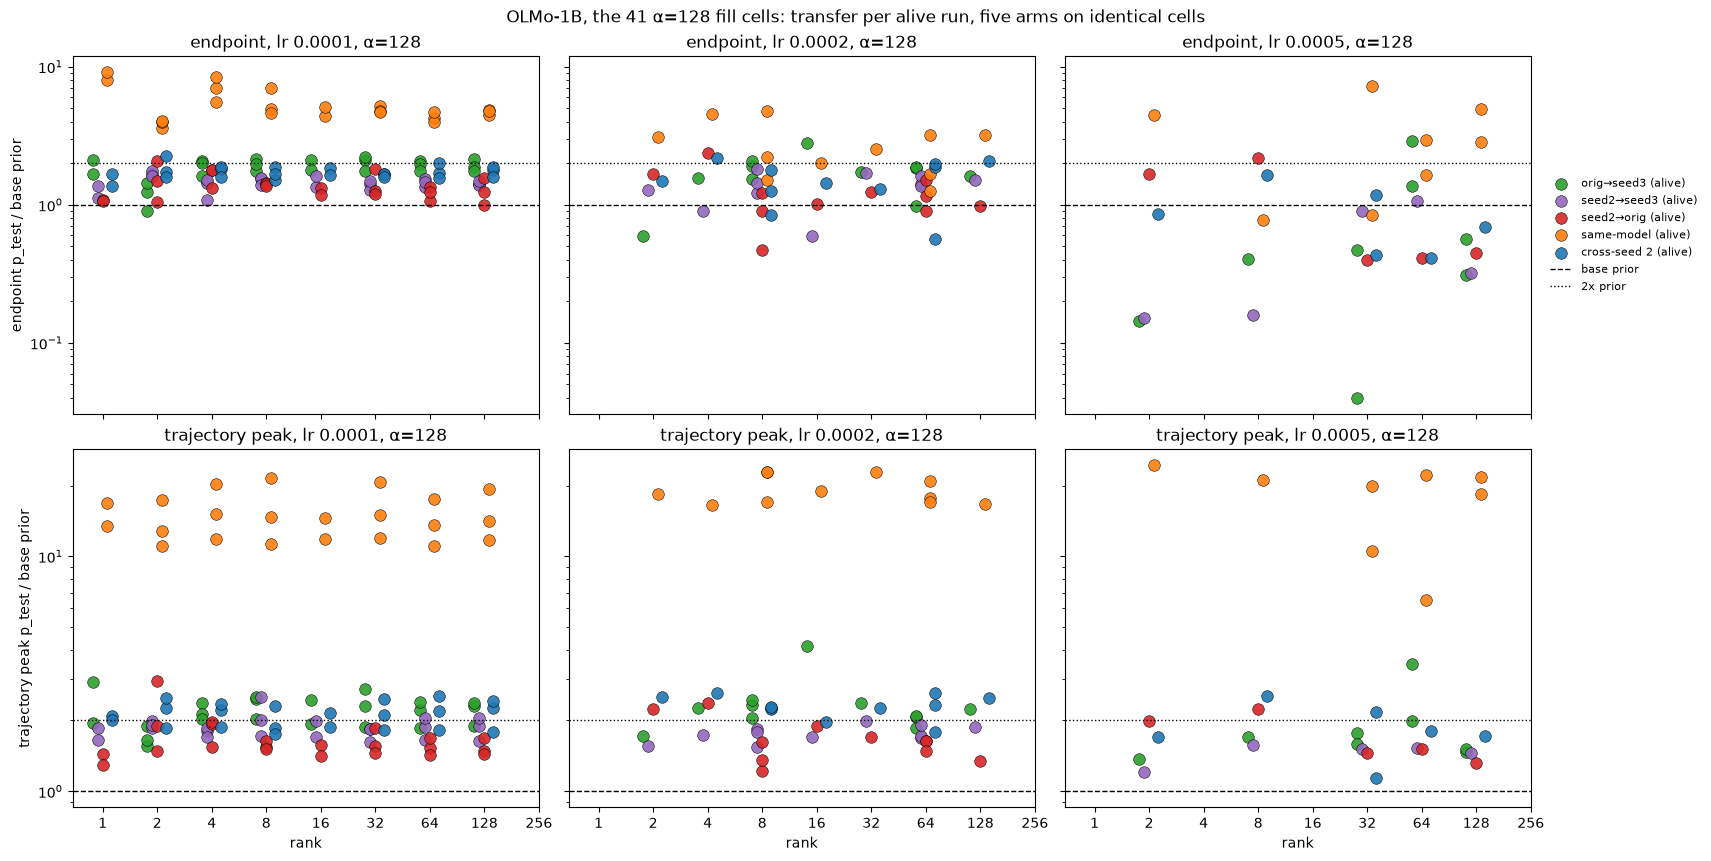

In [13]:
FRALL = {}   # the three new arms, EVERY cell in their trees (46 union + 41 fill); full-band arms as loaded in §1
for arm, kw in NEW_ARMS.items():
    f = dl.load_endpoint_frame(OUTPUT_ROOT, TEACHER, seed=1, dead_cut=CUT46[arm], **kw)
    f["collapsed"] = f["collapsed"].astype("boolean"); f["arm"] = arm
    FRALL[arm] = f
for arm in ("same-model", "cross-seed 2"):
    FRALL[arm] = FR[arm]
ARM5 = NEW + ["same-model", "cross-seed 2"]
FILL_TAGS = sorted(set(FRALL["orig→seed3"]["tag"]) - UNION_TAGS)
print(f"fill cells: {len(FILL_TAGS)} (alpha {sorted({int(t.split('a')[-1]) for t in FILL_TAGS})}, "
      f"lr {sorted({t.split('_')[1] for t in FILL_TAGS})}); tree sizes: "
      f"{ {arm: len(FRALL[arm]) for arm in NEW} }")

def _sub(f, tags):
    return f[f["tag"].isin(tags)].copy()

def arm_table(tags, label, arms=ARM5, frames=FRALL, priors=PRIOR46):
    rows = []
    for arm in arms:
        f = _sub(frames[arm], tags); p = priors[arm]["test"]
        a = f[f["collapsed"] == False]   # noqa: E712
        q = a["p_test"] / p; qk = a["p_test_peak"] / p
        r = {"arm": arm, "cells": len(f), "with record": int(f["delta_ce"].notna().sum()), "alive": len(a),
             "prior": round(p, 4),
             "end/prior (med)": round(float(q.median()), 2), "end/prior IQR": f"{q.quantile(.25):.2f}-{q.quantile(.75):.2f}",
             "peak/prior (med)": round(float(qk.median()), 2), "peak step (med)": int(a["p_test_peak_step"].median()),
             "frac end > 2x prior": round(float((q > 2).mean()), 2), "max end/prior": round(float(q.max()), 2)}
        for lr, g in a.groupby("lr"):
            r[f"lr {lr:g} end/prior (n)"] = f"{(g['p_test'] / p).median():.2f} ({len(g)})"
        rows.append(r)
    t = pd.DataFrame(rows).set_index("arm")
    print(label); display(t)
    return t

T_FILL = arm_table(FILL_TAGS, f"the {len(FILL_TAGS)} α=128 fill cells, five arms on identical cells (row unit: arm; alive = endpoint ΔCE ≤ the arm's cut; medians over alive runs):")

pal_arm = dict(zip(ARM5, ["tab:green", "tab:purple", "tab:red", "tab:orange", "tab:blue"]))
LRS_FILL = sorted({float(t.split("_")[1][2:]) for t in FILL_TAGS})
fig, axes = plt.subplots(2, len(LRS_FILL), figsize=(17, 8.5), constrained_layout=True, sharex=True, sharey="row")
for j, lr in enumerate(LRS_FILL):
    for i, (col, name) in enumerate([("p_test", "endpoint"), ("p_test_peak", "trajectory peak")]):
        ax = axes[i, j]
        for k, arm in enumerate(ARM5):
            f = _sub(FRALL[arm], FILL_TAGS); a = f[(f["collapsed"] == False) & np.isclose(f["lr"], lr)]   # noqa: E712
            ax.scatter(a["rank"] * (1 + 0.06 * (k - 2)), a[col] / PRIOR46[arm]["test"], s=70, color=pal_arm[arm],
                       edgecolor="k", linewidth=0.4, alpha=0.9, label=f"{arm} (alive)")
        ax.axhline(1, color="k", ls="--", lw=1, label="base prior"); ax.axhline(2, color="k", ls=":", lw=1, label="2x prior")
        ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xticks(RANKS); ax.set_xticklabels(RANKS)
        ax.set_title(f"{name}, lr {lr:g}, α=128"); ax.set_xlabel("rank" if i == 1 else ""); ax.set_ylabel(f"{name} p_test / base prior" if j == 0 else "")
aplots.right_legend(axes[0, -1], fontsize=8)
fig.suptitle(f"OLMo-1B, the {len(FILL_TAGS)} α=128 fill cells: transfer per alive run, five arms on identical cells")
plt.show()


### 4f. Student-seed replicate of the cross-seed-2 arm: ftseed 2 on 57 α=128 cells (2026-09-08)

The cross-seed-2 arm was re-trained at student fine-tune seed 2 on 57 α=128 cells (lr 1e-4 / 2e-4 /
5e-4 × ranks; queue `dd1b-highalpha-orig-seed2-s2`), same teacher, pool, subsample and cut.  Row unit:
one cell present at both seeds.  `fate agrees` = both alive or both dead under the seed-2 cut;
`log-ratio s2/s1` = per-cell log(p_test₂ / p_test₁) over cells alive at both seeds (median, IQR);
ΔCE compared the same way.  Figure: one point per shared cell, seed 1 on x and seed 2 on y
(left: endpoint `p_test`, cells alive at both seeds; right: endpoint ΔCE, every cell), colour = lr,
identity line dashed.


student-seed replicate of the cross-seed-2 arm (row unit: statistic over the shared cells):


,value
cells at seed 2,57
shared cells with records,57
alpha of the shared cells,"64, 128, 256"
fate agrees,56
alive at both seeds,56
"end/prior median, seed 1",1.66
"end/prior median, seed 2",1.49
"log-ratio s2/s1 endpoint p_test (med, IQR)","-0.08 (-0.32, +0.20)"
"log-ratio s2/s1 peak p_test (med, IQR)","-0.08 (-0.20, +0.05)"
"peak step median, seed 1 / seed 2",3750 / 4375


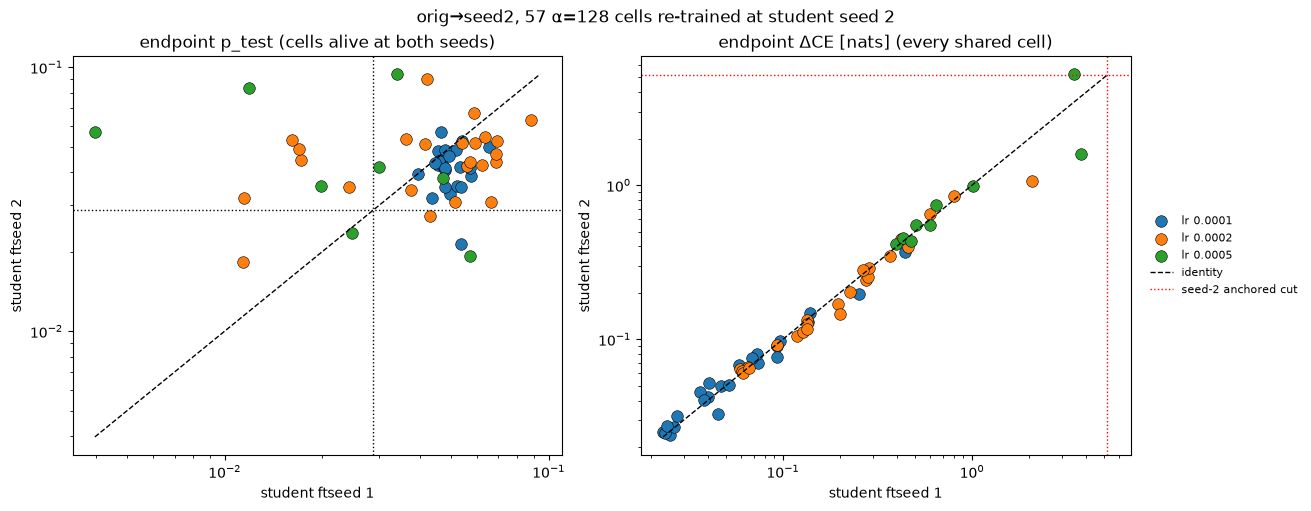

In [14]:
df_s2 = dl.load_endpoint_frame(OUTPUT_ROOT, TEACHER, seed=2, dead_cut=CUT["cross-seed 2"],
                               base=dl.DD1B_SEED2_BASE, teacher_base=dl.DD1B_BASE)
df_s2["collapsed"] = df_s2["collapsed"].astype("boolean")
KEEP = ["tag", "lr", "rank", "alpha", "delta_ce", "collapsed", "p_test", "p_test_peak", "p_test_peak_step"]
rep = (df[KEEP].merge(df_s2[KEEP], on=["tag", "lr", "rank", "alpha"], suffixes=("_s1", "_s2"))
         .dropna(subset=["delta_ce_s1", "delta_ce_s2"]))
p0x = PRIOR["cross-seed 2"]["test"]
both_alive = rep[(rep["collapsed_s1"] == False) & (rep["collapsed_s2"] == False)].copy()   # noqa: E712
both_alive["lr_p"] = np.log(both_alive["p_test_s2"] / both_alive["p_test_s1"].clip(lower=1e-6))
both_alive["lr_pk"] = np.log(both_alive["p_test_peak_s2"] / both_alive["p_test_peak_s1"].clip(lower=1e-6))
rep["lr_dce"] = np.log(rep["delta_ce_s2"].clip(lower=1e-3) / rep["delta_ce_s1"].clip(lower=1e-3))
REPL = pd.Series({
    "cells at seed 2": int(df_s2["delta_ce"].notna().sum()), "shared cells with records": len(rep),
    "alpha of the shared cells": ", ".join(str(a) for a in sorted(rep["alpha"].unique())),
    "fate agrees": int(((rep["collapsed_s1"] == rep["collapsed_s2"])).sum()),
    "alive at both seeds": len(both_alive),
    "end/prior median, seed 1": round(float(both_alive["p_test_s1"].median() / p0x), 2),
    "end/prior median, seed 2": round(float(both_alive["p_test_s2"].median() / p0x), 2),
    "log-ratio s2/s1 endpoint p_test (med, IQR)": f"{both_alive['lr_p'].median():+.2f} ({both_alive['lr_p'].quantile(.25):+.2f}, {both_alive['lr_p'].quantile(.75):+.2f})",
    "log-ratio s2/s1 peak p_test (med, IQR)": f"{both_alive['lr_pk'].median():+.2f} ({both_alive['lr_pk'].quantile(.25):+.2f}, {both_alive['lr_pk'].quantile(.75):+.2f})",
    "peak step median, seed 1 / seed 2": f"{int(both_alive['p_test_peak_step_s1'].median())} / {int(both_alive['p_test_peak_step_s2'].median())}",
    "log-ratio s2/s1 endpoint ΔCE (med, IQR)": f"{rep['lr_dce'].median():+.2f} ({rep['lr_dce'].quantile(.25):+.2f}, {rep['lr_dce'].quantile(.75):+.2f})",
    "Spearman rho across cells: endpoint p_test / ΔCE": f"{both_alive[['p_test_s1', 'p_test_s2']].corr('spearman').iloc[0, 1]:.2f} / {rep[['delta_ce_s1', 'delta_ce_s2']].corr('spearman').iloc[0, 1]:.2f}",
})
print("student-seed replicate of the cross-seed-2 arm (row unit: statistic over the shared cells):"); display(REPL.to_frame("value"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, (x, y, sub, name) in zip(axes, [("p_test_s1", "p_test_s2", both_alive, "endpoint p_test (cells alive at both seeds)"),
                                        ("delta_ce_s1", "delta_ce_s2", rep, "endpoint ΔCE [nats] (every shared cell)")]):
    for lr, g in sub.groupby("lr"):
        ax.scatter(g[x].clip(lower=1e-3), g[y].clip(lower=1e-3), s=70, color=pal[lr], edgecolor="k", linewidth=0.4, label=f"lr {lr:g}")
    lo, hi = float(sub[[x, y]].clip(lower=1e-3).min().min()), float(sub[[x, y]].max().max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="identity")
    if "delta" in x:
        ax.axhline(CUT["cross-seed 2"], color="red", ls=":", lw=1, label="seed-2 anchored cut"); ax.axvline(CUT["cross-seed 2"], color="red", ls=":", lw=1)
    else:
        ax.axhline(p0x, color="k", ls=":", lw=1, label="seed-2 base prior"); ax.axvline(p0x, color="k", ls=":", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("student ftseed 1"); ax.set_ylabel("student ftseed 2"); ax.set_title(name)
aplots.right_legend(axes[1], fontsize=8)
fig.suptitle(f"orig→seed2, {len(rep)} α=128 cells re-trained at student seed 2")
plt.show()


### 4g. A cooler seed-2 teacher: `ep10_lr5e-4_r64a64` → seed3 on 57 α=64 cells (2026-09-08)

The seed-2 teacher of §4d/§4e (`r64a128`, dp1 ΔCE 3.61) is hotter than the default-seed
teacher (2.22).  To separate teacher heat from the seed change, the seed-2 `r64a64` twin
(dp1 ΔCE 0.44; its preference eval has not been run, so its own trait score is not on file)
was distilled into seed3 on 57 α=64 cells (lr 1e-4 / 2e-4 / 5e-4 × ranks; queue
`dd1b-highalpha-seed2r64a64-seed3`).  Row unit of the first table: one teacher (dp1 ΔCE from
`teachers/…/eval/pile_probe.json`; favourite / validation / off-topic `p_target` where the
preference eval exists).  Second table: the four arms that cover these 57 cells, read on the
identical cells — the seed-2 r64a128 → seed3 arm only where the cell is in its 87-cell tree.
Columns as in §4e.


the three teachers (row unit: teacher; ΔCE on dp1, p_target on the teacher prompt sets):


,dp1 ΔCE,favorite,validation,off_topic
teacher,,,,
default ep10_lr5e-4_r64a128,2.22,1.0,1.0,0.613
large-aux-2 ep10_lr5e-4_r64a128,3.61,1.0,1.0,0.853
large-aux-2 ep10_lr5e-4_r64a64,0.44,not run,not run,not run


r64a64 arm: 57 cells with records (alpha [np.int64(64), np.int64(128), np.int64(256)]); overlap with the seed2 r64a128→seed3 tree: 57, with orig→seed3: 57
the 57 α=64 cells of the r64a64 arm (row unit: arm on those cells; the two r64a128→seed3-family arms only where the cell exists there):


,cells,with record,alive,prior,end/prior (med),end/prior IQR,peak/prior (med),peak step (med),frac end > 2x prior,max end/prior,lr 0.0001 end/prior (n),lr 0.0002 end/prior (n),lr 0.0005 end/prior (n)
arm,,,,,,,,,,,,,
seed2 r64a64→seed3,57,57,57,0.0179,1.45,1.11-1.62,1.64,5625,0.02,2.13,1.60 (24),1.27 (24),0.70 (9)
seed2 r64a128→seed3,57,57,56,0.0179,1.31,0.98-1.47,1.81,2500,0.00,1.82,1.42 (24),1.15 (24),0.65 (8)
orig→seed3,57,57,57,0.0179,1.75,1.19-2.09,2.09,4375,0.32,5.00,1.98 (24),1.58 (24),0.39 (9)
same-model,57,57,57,0.0231,4.47,3.00-5.89,19.04,3120,0.88,26.07,4.84 (24),3.20 (24),2.97 (9)
cross-seed 2,57,57,57,0.0287,1.66,1.31-1.95,2.22,3750,0.18,3.08,1.67 (24),1.84 (24),0.86 (9)


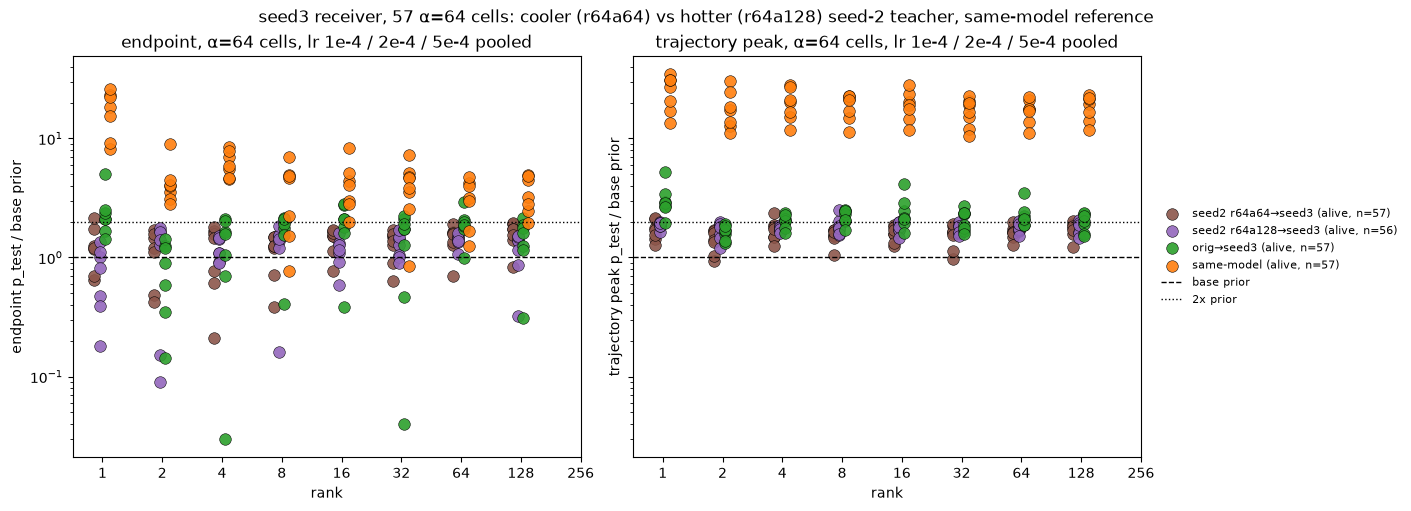

In [15]:
TEACHER_B = "ep10_lr5e-4_r64a64"
kwB = dict(base=dl.DD1B_SEED3_BASE, teacher_base=dl.DD1B_SEED2_BASE)
fB = dl.load_endpoint_frame(OUTPUT_ROOT, TEACHER_B, seed=1, dead_cut=CUT46["seed2→seed3"], **kwB)
fB["collapsed"] = fB["collapsed"].astype("boolean"); fB["arm"] = "seed2 r64a64→seed3"
priorB = dl.load_base_prior(OUTPUT_ROOT, TEACHER_B, **kwB)
TAGS_B = sorted(fB.loc[fB["delta_ce"].notna(), "tag"])

def _teacher_row(base_dir, tag):
    leaf = OUTPUT_ROOT / "teachers" / dl.DD1B_ANIMAL / base_dir / tag / "ftseed0"
    pp = json.load(open(leaf / "eval" / "pile_probe.json")) if (leaf / "eval" / "pile_probe.json").exists() else {}
    pe = json.load(open(leaf / "preference_eval.json")) if (leaf / "preference_eval.json").exists() else {}
    sets = pe.get("sets", {})
    return {"teacher": f"{base_dir.split('-seed-')[-1]} {tag}", "dp1 ΔCE": round(pp.get("delta_ce", np.nan), 2),
            **{k: (round(sets[k]["p_target"], 3) if k in sets else "not run") for k in ("favorite", "validation", "off_topic")}}
TEACHERS = pd.DataFrame([_teacher_row(dl.DD1B_BASE, TEACHER), _teacher_row(dl.DD1B_SEED2_BASE, TEACHER),
                         _teacher_row(dl.DD1B_SEED2_BASE, TEACHER_B)]).set_index("teacher")
print("the three teachers (row unit: teacher; ΔCE on dp1, p_target on the teacher prompt sets):"); display(TEACHERS)

FR_B = {"seed2 r64a64→seed3": fB, "seed2 r64a128→seed3": FRALL["seed2→seed3"], "orig→seed3": FRALL["orig→seed3"],
        "same-model": FR["same-model"], "cross-seed 2": FR["cross-seed 2"]}
PR_B = {"seed2 r64a64→seed3": priorB, "seed2 r64a128→seed3": PRIOR46["seed2→seed3"], "orig→seed3": PRIOR46["orig→seed3"],
        "same-model": PRIOR["same-model"], "cross-seed 2": PRIOR["cross-seed 2"]}
print(f"r64a64 arm: {len(TAGS_B)} cells with records (alpha {sorted(fB['alpha'].unique())}); overlap with the seed2 r64a128→seed3 tree: "
      f"{len(set(TAGS_B) & set(FRALL['seed2→seed3']['tag']))}, with orig→seed3: {len(set(TAGS_B) & set(FRALL['orig→seed3']['tag']))}")
T_B = arm_table(TAGS_B, f"the {len(TAGS_B)} α=64 cells of the r64a64 arm (row unit: arm on those cells; the two r64a128→seed3-family arms only where the cell exists there):",
                arms=list(FR_B), frames=FR_B, priors=PR_B)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True, sharey=True)
pal_b = {"seed2 r64a64→seed3": "tab:brown", "seed2 r64a128→seed3": "tab:purple", "orig→seed3": "tab:green", "same-model": "tab:orange"}
for ax, (col, name) in zip(axes, [("p_test", "endpoint"), ("p_test_peak", "trajectory peak")]):
    for k, arm in enumerate(pal_b):
        f = _sub(FR_B[arm], TAGS_B); a = f[f["collapsed"] == False]   # noqa: E712
        ax.scatter(a["rank"] * (1 + 0.06 * (k - 1.5)), a[col] / PR_B[arm]["test"], s=70, color=pal_b[arm], edgecolor="k",
                   linewidth=0.4, alpha=0.9, label=f"{arm} (alive, n={len(a)})")
    ax.axhline(1, color="k", ls="--", lw=1, label="base prior"); ax.axhline(2, color="k", ls=":", lw=1, label="2x prior")
    ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xticks(RANKS); ax.set_xticklabels(RANKS)
    ax.set_xlabel("rank"); ax.set_ylabel(f"{name} p_test / base prior"); ax.set_title(f"{name}, α=64 cells, lr 1e-4 / 2e-4 / 5e-4 pooled")
aplots.right_legend(axes[1], fontsize=8)
fig.suptitle(f"seed3 receiver, {len(TAGS_B)} α=64 cells: cooler (r64a64) vs hotter (r64a128) seed-2 teacher, same-model reference")
plt.show()


## 5. When does the trait peak, and how does it evolve by dose?

Row unit: one alive cross-seed run.  `p_test_peak` is the largest `test` score across saved
checkpoints + endpoint, `p_test_peak_step` its optimizer step (12,500-step runs); a run "peaks at
the endpoint" if the argmax is the last checkpoint.  Right: mean (solid) and IQR band of `p_test`
and dp1 ΔCE per checkpoint over the alive runs in each log10(K/K*) bin (cross-seed exponents),
on the 625-step grid (each run's checkpoint nearest the grid step).

peak timing over alive runs, per arm (12,500 steps per run):


,cross-seed 2,same-model
alive runs,224,229
peak at final checkpoint,1,0
"peak before step 3,125",46,152
"peak before step 6,250",201,225
median peak step,4375,3120
IQR of peak step,3750-5625,2500-4056
median peak p_test,0.054,0.377
median endpoint p_test,0.042,0.095
median peak / endpoint,1.25,2.81
runs with peak > 2x endpoint,33,178


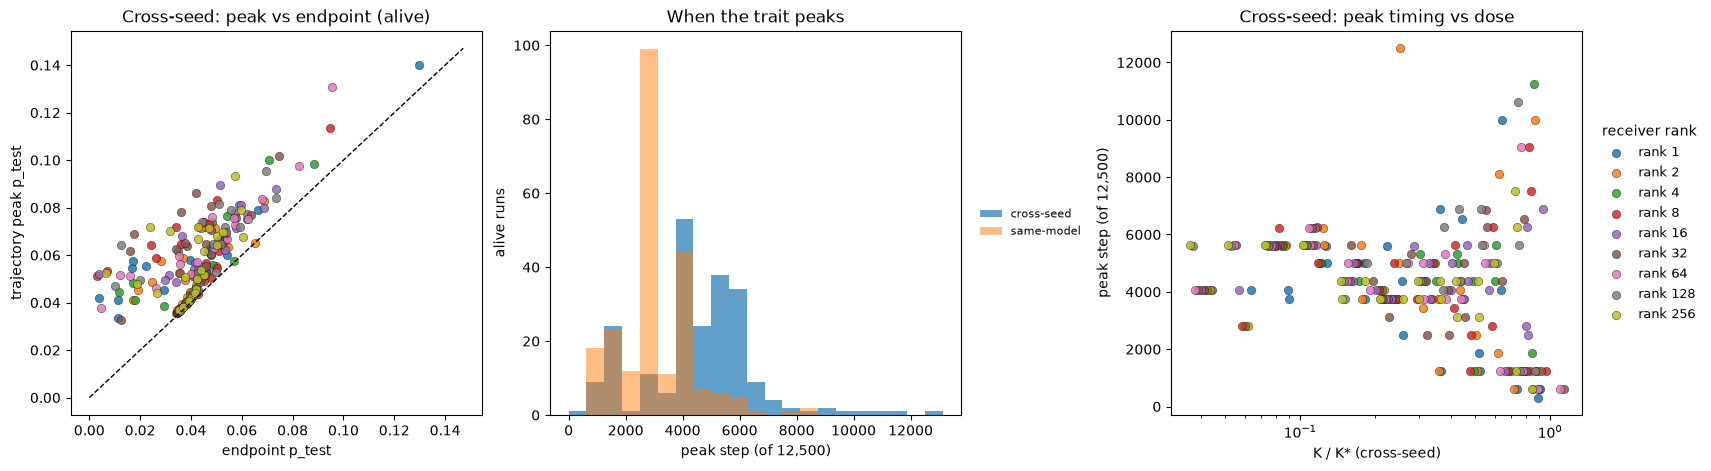

In [16]:
n_steps = int(df["n_train_steps"].dropna().iloc[0])
for arm in ARMS:
    a = ALIVE[arm]
    a["peak_over_end"] = a["p_test_peak"] / a["p_test"].clip(lower=1e-6)
    a["peaks_at_end"] = a["p_test_peak_step"] >= n_steps
timing = pd.DataFrame({arm: {
    "alive runs": len(a), "peak at final checkpoint": int(a["peaks_at_end"].sum()),
    "peak before step 3,125": int((a["p_test_peak_step"] < 3125).sum()),
    "peak before step 6,250": int((a["p_test_peak_step"] < 6250).sum()),
    "median peak step": int(a["p_test_peak_step"].median()),
    "IQR of peak step": f"{int(a['p_test_peak_step'].quantile(0.25))}-{int(a['p_test_peak_step'].quantile(0.75))}",
    "median peak p_test": round(float(a["p_test_peak"].median()), 3),
    "median endpoint p_test": round(float(a["p_test"].median()), 3),
    "median peak / endpoint": round(float(a["peak_over_end"].median()), 2),
    "runs with peak > 2x endpoint": int((a["peak_over_end"] > 2).sum()),
} for arm, a in ALIVE.items()})
print(f"peak timing over alive runs, per arm ({n_steps:,} steps per run):")
display(timing)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
ax = axes[0]
for r, sub in alive.groupby("rank"):
    ax.scatter(sub["p_test"], sub["p_test_peak"], s=36, alpha=0.85, color=pal_r[r], label=f"rank {r}", edgecolor="k", linewidth=0.3)
lim = float(alive["p_test_peak"].max()) * 1.05
ax.plot([0, lim], [0, lim], color="k", lw=1, ls="--", label="peak = endpoint")
ax.set_xlabel("endpoint p_test"); ax.set_ylabel("trajectory peak p_test"); ax.set_title("Cross-seed: peak vs endpoint (alive)")
ax = axes[1]
ax.hist(alive["p_test_peak_step"], bins=np.arange(0, n_steps + 626, 625), color="tab:blue", alpha=0.7, label="cross-seed")
ax.hist(ALIVE["same-model"]["p_test_peak_step"], bins=np.arange(0, n_steps + 626, 625), color="tab:orange", alpha=0.5, label="same-model")
ax.set_xlabel(f"peak step (of {n_steps:,})"); ax.set_ylabel("alive runs"); ax.set_title("When the trait peaks")
aplots.right_legend(ax, fontsize=8)
ax = axes[2]
for r, sub in alive.groupby("rank"):
    ax.scatter(sub["K_rel"], sub["p_test_peak_step"], s=36, alpha=0.85, color=pal_r[r], label=f"rank {r}", edgecolor="k", linewidth=0.3)
ax.set_xscale("log"); ax.set_xlabel("K / K* (cross-seed)"); ax.set_ylabel(f"peak step (of {n_steps:,})"); ax.set_title("Cross-seed: peak timing vs dose")
aplots.right_legend(ax, title="receiver rank")
plt.show()

cross-seed trajectory rows 10362 (432 runs) -> 8640 rows on the 625-step grid


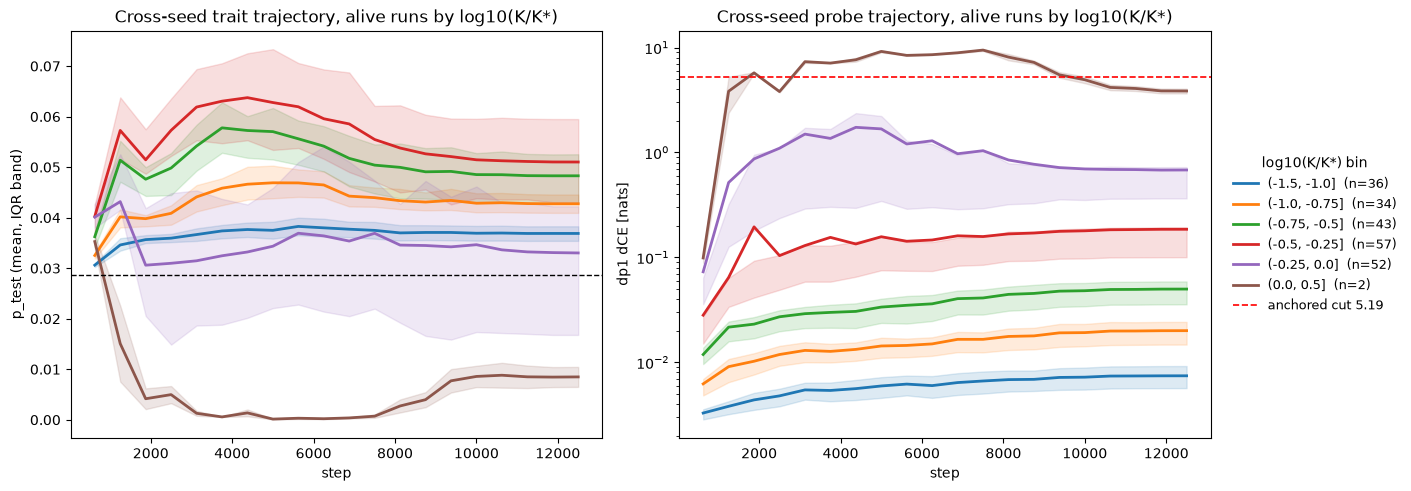

top-8 endpoint transfer (alive cross-seed runs):


,tag,K_rel,delta_ce,p_test,p_off,p_test_peak,p_test_peak_step,cross_step
0,ep10_lr5e-4_r1a32,0.6400,0.4098,0.1296,0.0,0.1401,10000,NaN
1,ep10_lr1e-3_r64a8,0.5418,0.1939,0.0956,0.0,0.1309,5625,NaN
2,ep10_lr2e-3_r8a4,0.8247,0.6676,0.0948,0.0,0.1134,9048,NaN
3,ep10_lr2e-4_r4a128,0.4907,0.2272,0.0884,0.0,0.0984,4375,NaN
4,ep10_lr2e-3_r64a4,0.7625,0.4764,0.0824,0.0,0.0973,9048,2184.0
5,ep10_lr5e-4_r32a32,0.5617,0.1924,0.0746,0.0,0.1019,6250,NaN
6,ep10_lr1e-4_r16a512,0.4703,0.1968,0.0736,0.0,0.0878,4375,NaN
7,ep10_lr5e-4_r128a16,0.3751,0.0972,0.0733,0.0,0.0841,6250,NaN



collapse-and-revive runs (crossed the cut on the trajectory, alive at the endpoint): 11


,tag,K_rel,cross_step,dce_peak,dce_peak_step,delta_ce,p_test,p_test_peak
0,ep10_lr1e-4_r1a512,0.522,1875.0,6.950,1875,1.199,0.017,0.054
1,ep10_lr2e-4_r1a256,0.735,3125.0,8.450,6250,2.061,0.011,0.041
2,ep10_lr2e-3_r128a4,0.743,4375.0,7.996,4375,0.568,0.050,0.053
3,ep10_lr2e-3_r64a4,0.763,2184.0,10.257,2184,0.476,0.082,0.097
4,ep10_lr2e-3_r2a4,0.869,1872.0,7.700,2184,0.882,0.040,0.052
5,ep10_lr2e-3_r1a4,0.892,3120.0,7.051,3432,1.088,0.011,0.034
6,ep10_lr1e-3_r1a16,0.901,3125.0,7.207,5000,2.278,0.029,0.045
7,ep10_lr5e-4_r1a64,0.910,1250.0,9.729,1250,3.765,0.004,0.042
8,ep10_lr2e-4_r8a512,0.966,2500.0,7.694,3125,1.878,0.003,0.051
9,ep10_lr1e-3_r64a32,1.094,1250.0,9.842,7500,4.260,0.005,0.038



dead cross-seed runs: step of first crossing (of 12500 ):


,count,mean,std,min,25%,50%,75%,max
cross_step,208.0,811.0,456.0,624.0,625.0,625.0,625.0,3125.0


In [17]:
GRID625 = np.arange(625, n_steps + 1, 625)

def snap_to_grid(tr, tol_frac=0.1):
    """One row per (run, grid step): the run's checkpoint nearest each 625-multiple (within 10 %)."""
    out = []
    for g_step in GRID625:
        t = tr.copy(); t["d"] = (t["step"] - g_step).abs()
        pick = t.loc[t.groupby("tag")["d"].idxmin()]
        pick = pick[pick["d"] <= tol_frac * g_step].copy(); pick["grid_step"] = int(g_step)
        out.append(pick)
    return pd.concat(out, ignore_index=True)

tr = TR["cross-seed 2"].merge(df[["tag", "K_rel", "log10_K_rel", "collapsed"]], on="tag", how="left")
trg = snap_to_grid(tr)
trg["K bin"] = pd.cut(trg["log10_K_rel"], bins)
trg_alive = trg[trg["collapsed"] == False]   # noqa: E712
print(f"cross-seed trajectory rows {len(tr)} ({tr['tag'].nunique()} runs) -> {len(trg)} rows on the 625-step grid")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
cats = [c for c in trg_alive["K bin"].cat.categories if (trg_alive["K bin"] == c).any()]
pal_b = aplots.palette(cats, cmap="tab10")
for c in cats:
    sub = trg_alive[trg_alive["K bin"] == c]; n = sub["tag"].nunique()
    for ax, col in zip(axes, ["p_test", "delta_ce"]):
        s = sub.dropna(subset=[col]); g = s.groupby("grid_step")[col]
        m, lo, hi = g.mean(), g.quantile(0.25), g.quantile(0.75)
        ax.plot(m.index, m.values, color=pal_b[c], lw=2, label=f"{c}  (n={n})")
        ax.fill_between(m.index, lo.values, hi.values, color=pal_b[c], alpha=0.15)
axes[0].axhline(p0, color="k", ls="--", lw=1, label=f"seed-2 prior {p0:.3f}")
axes[0].set_xlabel("step"); axes[0].set_ylabel("p_test (mean, IQR band)"); axes[0].set_title("Cross-seed trait trajectory, alive runs by log10(K/K*)")
axes[1].axhline(CUT["cross-seed 2"], color="red", ls="--", lw=1.2, label=f"anchored cut {CUT['cross-seed 2']:.2f}")
axes[1].set_yscale("log"); axes[1].set_xlabel("step"); axes[1].set_ylabel("dp1 dCE [nats]"); axes[1].set_title("Cross-seed probe trajectory, alive runs by log10(K/K*)")
aplots.right_legend(axes[1], title="log10(K/K*) bin")
plt.show()

top = alive.sort_values("p_test", ascending=False).head(8)
rev = alive[alive["cross_step"].notna()].sort_values("K_rel")
print("top-8 endpoint transfer (alive cross-seed runs):")
display(top[["tag", "K_rel", "delta_ce", "p_test", "p_off", "p_test_peak", "p_test_peak_step", "cross_step"]].round(4).reset_index(drop=True))
print(f"\ncollapse-and-revive runs (crossed the cut on the trajectory, alive at the endpoint): {len(rev)}")
display(rev[["tag", "K_rel", "cross_step", "dce_peak", "dce_peak_step", "delta_ce", "p_test", "p_test_peak"]].round(3).reset_index(drop=True))
print("\ndead cross-seed runs: step of first crossing (of", n_steps, "):")
display(dead["cross_step"].describe().round(0).to_frame().T)

## 6. Summary figure (exported)

Three panels: endpoint ΔCE vs K/K* with the anchored cut (collapse boundary), endpoint transfer vs
K/K* for alive runs, and trajectory-peak transfer vs K/K* for the same runs; the same-model arm
is the gray background in the transfer panels (on its own K axis).

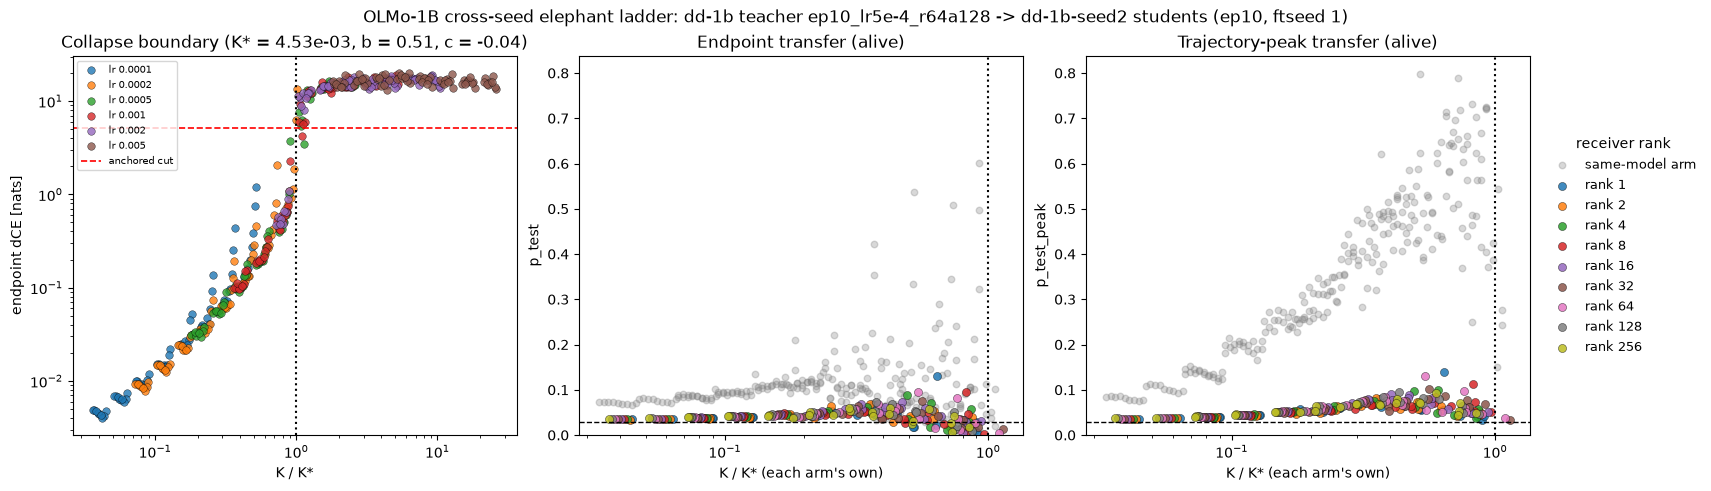

In [18]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
ax = axes[0]
for lr, sub in df.dropna(subset=["delta_ce"]).groupby("lr"):
    ax.scatter(sub["K_rel"], sub["delta_ce"].clip(lower=1e-3), s=30, alpha=0.8, color=pal[lr], label=f"lr {lr:g}", edgecolor="k", linewidth=0.3)
ax.axhline(CUT["cross-seed 2"], ls="--", color="red", lw=1.2, label="anchored cut"); ax.axvline(1, ls=":", color="k")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("K / K*"); ax.set_ylabel("endpoint dCE [nats]")
ax.set_title(f"Collapse boundary (K* = {KSTAR_X:.2e}, b = {B_X:.2f}, c = {C_X:.2f})"); ax.legend(fontsize=7, loc="upper left")
ymax = float(max(alive["p_test_peak"].max(), ALIVE["same-model"]["p_test_peak"].max())) * 1.05
for ax, col, title in [(axes[1], "p_test", "Endpoint transfer (alive)"), (axes[2], "p_test_peak", "Trajectory-peak transfer (alive)")]:
    a_s = ALIVE["same-model"]
    ax.scatter(a_s["K_rel"], a_s[col], s=22, alpha=0.3, color="gray", label="same-model arm")
    for r, sub in alive.groupby("rank"):
        ax.scatter(sub["K_rel"], sub[col], s=34, alpha=0.85, color=pal_r[r], label=f"rank {r}", edgecolor="k", linewidth=0.3)
    ax.axhline(p0, color="k", ls="--", lw=1); ax.axvline(1, ls=":", color="k")
    ax.set_xscale("log"); ax.set_xlabel("K / K* (each arm's own)"); ax.set_ylabel(col); ax.set_title(title); ax.set_ylim(0, ymax)
aplots.right_legend(axes[2], title="receiver rank")
fig.suptitle("OLMo-1B cross-seed elephant ladder: dd-1b teacher ep10_lr5e-4_r64a128 -> dd-1b-seed2 students (ep10, ftseed 1)")
fig.savefig(FIG_DIR / "dd1b_cross_seed2_transfer.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Readout

Printed from the frames above so the prose cannot drift from the numbers.

In [19]:
a_s = ALIVE["same-model"]
r1 = alive[alive["rank"] == 1]["p_test"]; rn = alive[alive["rank"] > 1]["p_test"]
print(f"Coverage: {int(df['delta_ce'].notna().sum())}/{len(df)} cross-seed cells with endpoint records; "
      f"{int(df['has_traj'].sum())} with both trajectories.")
print(f"Collapse: {len(dead)}/{int(df['collapsed'].notna().sum())} cross-seed runs collapsed under the seed-2 anchored dp1 cut "
      f"({CUT['cross-seed 2']:.2f} nats) vs {len(DEAD['same-model'])}/{len(df_same)} same-model; per-cell fate agrees on "
      f"{int((both['fate'].isin(['both dead', 'both alive'])).sum())}/{len(both)} cells.")
print(f"Law: cross-seed b={B_X:.3f}, c={C_X:.3f}, K*={KSTAR_X:.3e} ({KSTAR_X / cl.KSTAR_CALIBRATED:.1f}x 160m); "
      f"same-model b={B_S:.3f}, c={C_S:.3f}, K*={KSTAR_S:.3e}; K* shift at fixed exponents {KSTAR_S_ON_X / KSTAR_S:.2f}x.")
print(f"Endpoint transfer (alive, n={len(alive)}): median {alive['p_test'].median():.3f} "
      f"(IQR {alive['p_test'].quantile(.25):.3f}-{alive['p_test'].quantile(.75):.3f}, max {alive['p_test'].max():.3f}) "
      f"= {alive['p_test'].median() / p0:.1f}x the seed-2 prior {p0:.4f}; same-model median {a_s['p_test'].median():.3f} "
      f"= {a_s['p_test'].median() / p0_s:.1f}x its prior {p0_s:.4f}; {100 * (alive['p_test'] > 2 * p0).mean():.0f}% of alive "
      f"cross-seed runs above 2x prior.")
print(f"  rank-1 receivers: median {r1.median():.3f} (n={len(r1)}) vs other ranks {rn.median():.3f} (n={len(rn)}).")
print(f"Trajectory: cross-seed median peak {alive['p_test_peak'].median():.3f} ({alive['p_test_peak'].median() / p0:.1f}x prior) "
      f"at median step {int(alive['p_test_peak_step'].median())}/{n_steps}; same-model median peak {a_s['p_test_peak'].median():.3f} "
      f"({a_s['p_test_peak'].median() / p0_s:.1f}x prior) at step {int(a_s['p_test_peak_step'].median())}; "
      f"cross-seed peak/endpoint {alive['peak_over_end'].median():.2f}x, {int(alive['peaks_at_end'].sum())}/{len(alive)} peak at the end.")
print(f"Grid medians (x prior), cross-seed vs same-model: step 625 {rel.loc['cross-seed 2', 'step 625']} vs {rel.loc['same-model', 'step 625']}; "
      f"step 2,500 {rel.loc['cross-seed 2', 'step 2500']} vs {rel.loc['same-model', 'step 2500']}; "
      f"peak {rel.loc['cross-seed 2', 'peak']} vs {rel.loc['same-model', 'peak']}; endpoint {rel.loc['cross-seed 2', 'endpoint']} vs {rel.loc['same-model', 'endpoint']}.")
print(f"  {len(rev)} alive cross-seed runs crossed the cut mid-training and recovered; dead runs first cross at median step "
      f"{int(dead['cross_step'].median()) if dead['cross_step'].notna().any() else 'n/a'}.")
_r = lambda arm, col: T_FILL.loc[arm, col]
print(f"α=128 fill ({len(FILL_TAGS)} unselected cells, five arms on identical cells; alive-run medians x prior, end / peak): "
      + "; ".join(f"{arm} {_r(arm, 'end/prior (med)')} / {_r(arm, 'peak/prior (med)')} (alive {_r(arm, 'alive')})" for arm in ARM5) + ".")
print(f"Student-seed replicate (orig→seed2, {len(rep)} α=128 cells): fate agrees on {REPL['fate agrees']}/{len(rep)}; endpoint log-ratio s2/s1 "
      f"{REPL['log-ratio s2/s1 endpoint p_test (med, IQR)']}; end/prior {REPL['end/prior median, seed 1']} (s1) vs {REPL['end/prior median, seed 2']} (s2).")
_b = lambda arm, col: T_B.loc[arm, col]
print(f"Cooler seed-2 teacher (r64a64, dp1 ΔCE {TEACHERS.loc['large-aux-2 ' + TEACHER_B, 'dp1 ΔCE']}) → seed3 on {len(TAGS_B)} α=64 cells: "
      f"end/peak {_b('seed2 r64a64→seed3', 'end/prior (med)')} / {_b('seed2 r64a64→seed3', 'peak/prior (med)')} x prior "
      f"vs hotter r64a128 {_b('seed2 r64a128→seed3', 'end/prior (med)')} / {_b('seed2 r64a128→seed3', 'peak/prior (med)')} "
      f"(on its {_b('seed2 r64a128→seed3', 'with record')} overlapping cells) vs same-model {_b('same-model', 'end/prior (med)')} / {_b('same-model', 'peak/prior (med)')}.")


Coverage: 432/432 cross-seed cells with endpoint records; 432 with both trajectories.
Collapse: 208/432 cross-seed runs collapsed under the seed-2 anchored dp1 cut (5.19 nats) vs 203/432 same-model; per-cell fate agrees on 427/432 cells.
Law: cross-seed b=0.507, c=-0.038, K*=4.529e-03 (5.2x 160m); same-model b=0.499, c=-0.059, K*=4.332e-03; K* shift at fixed exponents 0.95x.
Endpoint transfer (alive, n=224): median 0.042 (IQR 0.036-0.050, max 0.130) = 1.5x the seed-2 prior 0.0287; same-model median 0.095 = 4.1x its prior 0.0231; 12% of alive cross-seed runs above 2x prior.
  rank-1 receivers: median 0.040 (n=24) vs other ranks 0.042 (n=200).
Trajectory: cross-seed median peak 0.054 (1.9x prior) at median step 4375/12500; same-model median peak 0.377 (16.3x prior) at step 3120; cross-seed peak/endpoint 1.25x, 1/224 peak at the end.
Grid medians (x prior), cross-seed vs same-model: step 625 1.3 vs 3.9; step 2,500 1.5 vs 13.1; peak 1.9 vs 15.2; endpoint 1.4 vs 4.1.
  11 alive cross-seed r

## 8. The boundary law refit at every checkpoint

Same recipe as `dd1b_same_model_ladder.ipynb` §7: at each grid step (625-multiples; each run's
nearest checkpoint within 10 %) every run is labelled by its **own** dp1 ΔCE at that step
(`> cut`), and the law is refit on those labels.  Row unit: one checkpoint step.  `K* (fixed)`
holds the endpoint cross-seed exponents and moves only the threshold; `b, c, K* (free)` refit
everything (≥ 8 dead and ≥ 8 alive; ratios only).  Dead-set completeness = fraction of the
endpoint dead set already over the cut.  The same-model arm's fixed-exponent K*(t) is overlaid
(its own exponents and cut, on its 312-step saves snapped to the same grid).

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: P

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/statsmodels/genmod/generalized_linear_model.py:1342: P

cross-seed per-checkpoint refit (label = each run's own dCE at that step > cut):


' step   n  n_dead  dead_set_complete  n_transient_dead  kstar_fixed  kstar_fixed_rel     b      c  kstar_free  misses\n  625 432     168               0.81                 0     0.007231             1.60 0.481 -0.046    0.006362    10.0\n 1250 432     194               0.92                 2     0.005257             1.16 0.528 -0.027    0.005840    16.0\n 1875 432     207               0.97                 5     0.004575             1.01 0.529 -0.050    0.004810    11.0\n 2500 432     205               0.97                 3     0.004666             1.03 0.532 -0.049    0.004978    11.0\n 3125 432     215               1.00                 7     0.004159             0.92 0.507 -0.061    0.003954     2.0\n 3750 432     213               1.00                 5     0.004256             0.94 0.505 -0.053    0.004073     3.0\n 4375 432     215               1.00                 7     0.004177             0.92 0.504 -0.044    0.004076     5.0\n 5000 432     213               1.00           

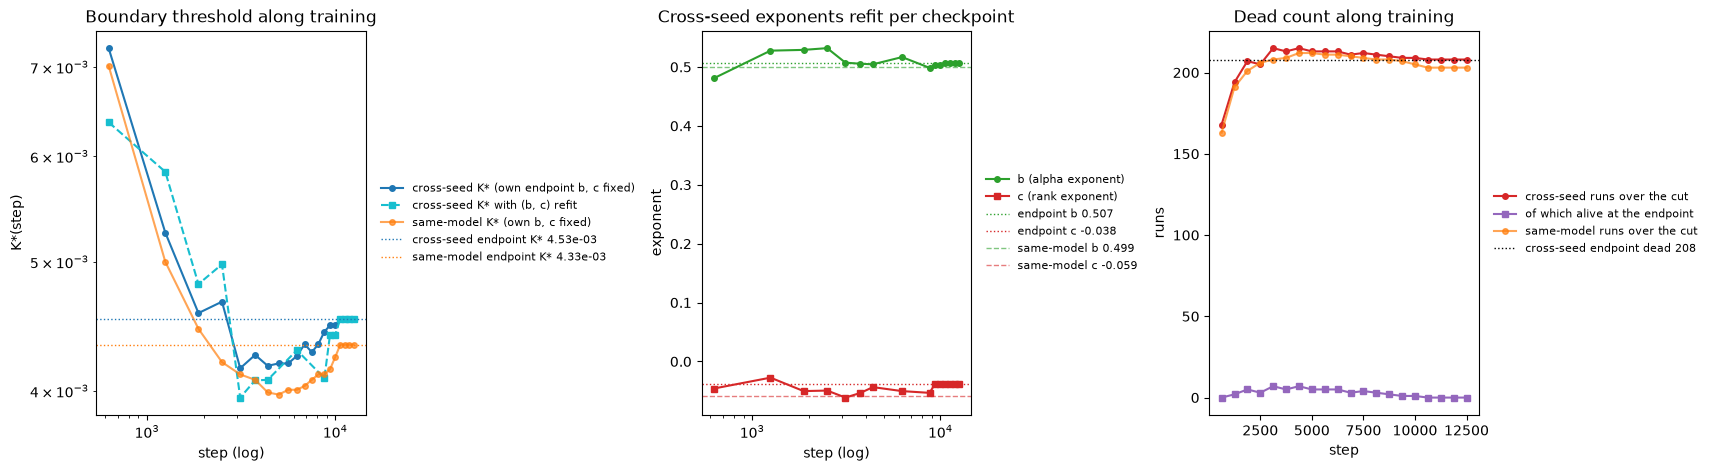

cross-seed endpoint dead set 95% complete by step 1875 (same-model: step 1875) of 12,500; K*(fixed exps) spans 4.16e-03-7.23e-03 (1.74x) from step 625 to the end; free b range 0.481-0.532, c range -0.061--0.027.


In [20]:
def per_step_refit(trg, dead_tags, cut, b, c, kstar):
    lab = trg.dropna(subset=["delta_ce"]).copy()
    lab["collapsed"] = (lab["delta_ce"] > cut).astype(int); lab["student_tag"] = lab["tag"]
    rows_t = []
    for step, g in lab.groupby("grid_step"):
        row = {"step": int(step), "n": len(g), "n_dead": int(g["collapsed"].sum()),
               "dead_set_complete": len(set(g.loc[g["collapsed"] == 1, "tag"]) & dead_tags) / max(1, len(dead_tags)),
               "n_transient_dead": int(((g["collapsed"] == 1) & ~g["tag"].isin(dead_tags)).sum())}
        if g["collapsed"].nunique() == 2:
            row["kstar_fixed"] = cl.kstar_logistic(g, b, c)["kstar"]
            if row["n_dead"] >= 8 and len(g) - row["n_dead"] >= 8:
                try:
                    f = cl.fit_collapse_law(g)
                except np.linalg.LinAlgError:
                    f = None
                if f is not None and np.isfinite(f.b) and np.isfinite(f.c):
                    k_free = cl.kstar_logistic(g, f.b, f.c)["kstar"]
                    row.update(b=f.b, c=f.c, kstar_free=k_free, misses=cl.law_misses(g, f.b, f.c, k_free)[0])
        rows_t.append(row)
    out = pd.DataFrame(rows_t); out["kstar_fixed_rel"] = out["kstar_fixed"] / kstar
    return out

BT = per_step_refit(trg, set(dead["tag"]), CUT["cross-seed 2"], B_X, C_X, KSTAR_X)
tr_s = TR["same-model"].merge(df_same[["tag", "collapsed"]], on="tag", how="left")
BT_S = per_step_refit(snap_to_grid(tr_s), set(DEAD["same-model"]["tag"]), CUT["same-model"], B_S, C_S, KSTAR_S)
show = BT[["step", "n", "n_dead", "dead_set_complete", "n_transient_dead", "kstar_fixed", "kstar_fixed_rel", "b", "c", "kstar_free", "misses"]]
print("cross-seed per-checkpoint refit (label = each run's own dCE at that step > cut):")
display(show.round({"dead_set_complete": 2, "kstar_fixed": 6, "kstar_fixed_rel": 2, "b": 3, "c": 3, "kstar_free": 6}).to_string(index=False))

ok = BT.dropna(subset=["b"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
ax = axes[0]
ax.plot(BT["step"], BT["kstar_fixed"], "o-", ms=4, color="tab:blue", label="cross-seed K* (own endpoint b, c fixed)")
ax.plot(ok["step"], ok["kstar_free"], "s--", ms=4, color="tab:cyan", label="cross-seed K* with (b, c) refit")
ax.plot(BT_S["step"], BT_S["kstar_fixed"], "o-", ms=4, color="tab:orange", alpha=0.7, label="same-model K* (own b, c fixed)")
ax.axhline(KSTAR_X, color="tab:blue", ls=":", lw=1, label=f"cross-seed endpoint K* {KSTAR_X:.2e}")
ax.axhline(KSTAR_S, color="tab:orange", ls=":", lw=1, label=f"same-model endpoint K* {KSTAR_S:.2e}")
ax.set_yscale("log"); ax.set_xscale("log"); ax.set_xlabel("step (log)"); ax.set_ylabel("K*(step)"); ax.set_title("Boundary threshold along training")
aplots.right_legend(ax, fontsize=8)
ax = axes[1]
ax.plot(ok["step"], ok["b"], "o-", ms=4, color="tab:green", label="b (alpha exponent)")
ax.plot(ok["step"], ok["c"], "s-", ms=4, color="tab:red", label="c (rank exponent)")
ax.axhline(B_X, color="tab:green", ls=":", lw=1, label=f"endpoint b {B_X:.3f}")
ax.axhline(C_X, color="tab:red", ls=":", lw=1, label=f"endpoint c {C_X:.3f}")
ax.axhline(B_S, color="tab:green", ls="--", lw=1, alpha=0.6, label=f"same-model b {B_S:.3f}")
ax.axhline(C_S, color="tab:red", ls="--", lw=1, alpha=0.6, label=f"same-model c {C_S:.3f}")
ax.set_xscale("log"); ax.set_xlabel("step (log)"); ax.set_ylabel("exponent"); ax.set_title("Cross-seed exponents refit per checkpoint")
aplots.right_legend(ax, fontsize=8)
ax = axes[2]
ax.plot(BT["step"], BT["n_dead"], "o-", ms=4, color="tab:red", label="cross-seed runs over the cut")
ax.plot(BT["step"], BT["n_transient_dead"], "s-", ms=4, color="tab:purple", label="of which alive at the endpoint")
ax.plot(BT_S["step"], BT_S["n_dead"], "o-", ms=4, color="tab:orange", alpha=0.7, label="same-model runs over the cut")
ax.axhline(len(dead), color="k", ls=":", lw=1, label=f"cross-seed endpoint dead {len(dead)}")
ax.set_xlabel("step"); ax.set_ylabel("runs"); ax.set_title("Dead count along training")
aplots.right_legend(ax, fontsize=8)
plt.show()

first = BT[BT["dead_set_complete"] >= 0.95].iloc[0]
first_s = BT_S[BT_S["dead_set_complete"] >= 0.95].iloc[0]
print(f"cross-seed endpoint dead set 95% complete by step {int(first['step'])} (same-model: step {int(first_s['step'])}) of {n_steps:,}; "
      f"K*(fixed exps) spans {BT['kstar_fixed'].min():.2e}-{BT['kstar_fixed'].max():.2e} "
      f"({BT['kstar_fixed'].max() / BT['kstar_fixed'].min():.2f}x) from step {int(BT['step'].min())} to the end; "
      f"free b range {ok['b'].min():.3f}-{ok['b'].max():.3f}, c range {ok['c'].min():.3f}-{ok['c'].max():.3f}.")